# Cattle keypoint detection

A standalone Python **3.11** notebook using PyTorch and torchvision, without the reference repository's legacy MMPose/MMCV environment. Run cells in order.

**Scope:** 18-point top-down pose estimation given a cattle bounding box. Evaluation uses ground-truth boxes, so these results measure localization, not full-image cattle detection. ImageNet pretraining supplies generic features; cattle supervision comes exclusively from the reference dataset.

**Attribution:** Wang et al., *Performance evaluation of a state-of-the-art keypoint detection method for precision livestock farming*, Computers and Electronics in Agriculture 240 (2026), 111230. [Repository](https://github.com/yww0411/Livestock-keypoint-detection), [paper](https://doi.org/10.1016/j.compag.2025.111230). Dataset: CC BY 4.0; reference code: MIT. Data downloads are commit-pinned and retain the license.

## 1. Environment and configuration

Use the existing Python 3.11 kernel. No automatic package upgrades. Tested: Python 3.11.4, torch 2.2.0+cu121, torchvision 0.17.0+cu121, NumPy 1.26.4. Also uses installed Pillow, OpenCV, pandas, matplotlib, tqdm and Jupyter.

Default: 100 epochs, validation early stopping. Pause/resume and monitoring instructions appear before the training cell. Keep one trainer per run directory.

In [1]:
from pathlib import Path
import sys, os, json, random, hashlib, time, platform
from collections import Counter
import numpy as np
import pandas as pd
# Load the native renderer before torch/OpenCV to avoid a Windows DLL import-order crash.
from matplotlib.backends.backend_agg import FigureCanvasAgg
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from tqdm.auto import tqdm
from IPython.display import display

ROOT=Path.cwd().resolve()
if ROOT.name=='ml': ROOT=ROOT.parent
assert (ROOT/'ml').is_dir(), 'Open from the repository root or ml directory.'
CFG=dict(seed=3407,fold='p1A',width=256,height=192,batch_size=16,epochs=100,
         patience=20,lr=.0003,weight_decay=.0001,freeze_epochs=4,sigma=1.5,crop_padding=1.25,pretrained=True)
COMMIT='d2fbc81e6181751f2e65eb6e393b10a9c7e16dfe'
DATA=ROOT/'ml/data/reference'; CATTLE=DATA/'data_process/cattle'
RUN=ROOT/'ml/runs/cattle_resnet18_p1A'; RUN.mkdir(parents=True,exist_ok=True)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random.seed(CFG['seed']); np.random.seed(CFG['seed']); torch.manual_seed(CFG['seed'])
if torch.cuda.is_available(): torch.cuda.manual_seed_all(CFG['seed'])
torch.set_num_threads(min(4,os.cpu_count() or 1))
torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True
ENV=dict(python=sys.version,torch=torch.__version__,device=str(DEVICE),numpy=np.__version__,
         gpu=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,platform=platform.platform())
print(json.dumps(ENV,indent=2)); print('Run folder:',RUN)
assert sys.version_info>=(3,10)

{
  "python": "3.11.4 (tags/v3.11.4:d2340ef, Jun  7 2023, 05:45:37) [MSC v.1934 64 bit (AMD64)]",
  "torch": "2.2.0+cu121",
  "device": "cuda",
  "numpy": "1.26.4",
  "gpu": "NVIDIA GeForce RTX 3060 Laptop GPU",
  "platform": "Windows-10-10.0.26300-SP0"
}
Run folder: C:\Users\sam\Documents\GitHub\holycow\ml\runs\cattle_resnet18_p1A


## 2. Import the reference data

Download only cattle data, attribution and the license (about 133 MB). All files are verified with their Git blob hashes. Downloads use temporary files and retry transient errors. No upstream training code is executed.

In [2]:
import urllib.request
from concurrent.futures import ThreadPoolExecutor
BASE=f'https://raw.githubusercontent.com/yww0411/Livestock-keypoint-detection/{COMMIT}/'
def get_bytes(url):
    for attempt in range(4):
        try:
            with urllib.request.urlopen(url,timeout=90) as response: return response.read()
        except Exception:
            if attempt==3: raise
            time.sleep(2**attempt)
manifest_path=DATA/'manifest.json'
if manifest_path.exists():
    manifest=json.loads(manifest_path.read_text()); assert manifest['sha']==COMMIT
else:
    manifest=json.loads(get_bytes(f'https://api.github.com/repos/yww0411/Livestock-keypoint-detection/git/trees/{COMMIT}?recursive=1'))
    assert not manifest.get('truncated')
    DATA.mkdir(parents=True,exist_ok=True); manifest_path.write_text(json.dumps(manifest))
files=[x for x in manifest['tree'] if x['type']=='blob' and
       (x['path'].startswith('data_process/cattle/') or x['path'] in ('README.md','LICENSE-DATA.txt'))]
def git_hash(b): return hashlib.sha1(f'blob {len(b)}\0'.encode()+b).hexdigest()
def download_one(item):
    path=DATA/item['path']
    if path.exists() and git_hash(path.read_bytes())==item['sha']: return
    content=get_bytes(BASE+item['path']); assert git_hash(content)==item['sha'], f'Integrity failure: {path}'
    path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix(path.suffix+'.part'); tmp.write_bytes(content); tmp.replace(path)
with ThreadPoolExecutor(max_workers=8) as pool:
    list(tqdm(pool.map(download_one,files),total=len(files),desc='Verify/download cattle data'))
provenance=dict(repository='https://github.com/yww0411/Livestock-keypoint-detection',commit=COMMIT,dataset_license='CC BY 4.0',files=len(files))
(DATA/'source.json').write_text(json.dumps(provenance,indent=2))
print((DATA/'LICENSE-DATA.txt').read_text())

Verify/download cattle data:   0%|          | 0/902 [00:00<?, ?it/s]

Dataset License (CC BY 4.0)

This dataset (v1.0) is licensed under the Creative Commons Attribution 4.0
International License (CC BY 4.0).

You are free to:
- Share: copy and redistribute the material in any medium or format
- Adapt: remix, transform, and build upon the material for any purpose, even commercially

Under the following terms:
- Attribution: You must give appropriate credit, provide a link to the license,
  and indicate if changes were made.

To view a copy of this license, visit:
https://creativecommons.org/licenses/by/4.0/

Recommended attribution:
"Yiwei Wang et al., LivestockKeypoints, v1.0, licensed under CC BY 4.0."



## 3. Validate data and train/validation/test separation

Use the published **p1A** protocol: train/validation use source groups B/C; test uses held-out group A. Validate decoded image dimensions, annotation IDs, cattle categories, keypoint names, boxes, coordinates and visibility. Invalid input raises an error.

The published split has nine original filename groups shared by train and validation. Conservatively move training members of these groups into validation; leave test unchanged. Filenames can collide across sources, so this is a precaution, not proof of duplicate content. Exact hashes and original filenames must then be disjoint. Save the actual split manifest and fingerprint. These checks cannot exclude different frames of the same animal/video because upstream recording/animal identities are unavailable. This is a source-group holdout, not a verified animal-independent split. Test labels are not used for training or model selection.

In [3]:
NAMES=['mouth','eye','ear','neck','shoulder','chest','hip','tail','elbow','l_fore_wrist',
       'l_fore_foot','r_fore_wrist','r_fore_foot','hind_knee','l_hind_hock','l_hind_foot','r_hind_hock','r_hind_foot']
K=len(NAMES); records={}; audit=[]
for split in ('train','val','test'):
    coco=json.loads((CATTLE/'annotations_p1'/f"cattle_{CFG['fold']}_{split}.json").read_text())
    images={i['id']:i for i in coco['images']}
    assert len(images)==len(coco['images'])
    assert len({a['id'] for a in coco['annotations']})==len(coco['annotations'])
    cats={c['id']:c for c in coco['categories']}; rows=[]
    for a in coco['annotations']:
        assert a['image_id'] in images
        assert cats[a['category_id']]['name'].lower()=='cattle'
        assert cats[a['category_id']]['keypoints']==NAMES
        im=images[a['image_id']]; path=(CATTLE/im['file_name']).resolve()
        assert path.is_relative_to(CATTLE.resolve())
        with Image.open(path) as pil:
            pil.load(); assert pil.size==(im['width'],im['height'])
        kp=np.asarray(a['keypoints'],dtype=np.float32).reshape(K,3)
        box=np.asarray(a['bbox'],dtype=np.float32)
        assert np.isfinite(kp).all() and np.isfinite(box).all()
        assert set(kp[:,2]).issubset({0.,1.,2.})
        m=kp[:,2]>0; assert m.any() and int(m.sum())==a['num_keypoints']
        assert (kp[m,:2]>=0).all()
        # COCO coordinates are continuous; points on width/height boundaries are valid.
        assert (kp[m,0]<=im['width']).all() and (kp[m,1]<=im['height']).all()
        x,y,w,h=box
        assert x>=0 and y>=0 and w>0 and h>0
        assert x+w<=im['width']+1 and y+h<=im['height']+1
        original=im.get('extra',{}).get('name',Path(im['file_name']).name.split('.rf.')[0])
        rows.append(dict(image_id=im['id'],annotation_id=a['id'],path=str(path),file_name=im['file_name'],
                         group=im['batch_id'],original=original.lower(),sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                         bbox=box.tolist(),keypoints=kp.tolist()))
    records[split]=rows
    audit.append(dict(split=split,images=len(images),animals=len(rows),
                      labeled=sum(np.count_nonzero(np.array(r['keypoints'])[:,2]) for r in rows),
                      visible=sum(np.count_nonzero(np.array(r['keypoints'])[:,2]==2) for r in rows),
                      groups=dict(Counter(r['group'] for r in rows))))
colliding={r['original'] for r in records['train']} & {r['original'] for r in records['val']}
moved=[r for r in records['train'] if r['original'] in colliding]
records['train']=[r for r in records['train'] if r['original'] not in colliding]
records['val'].extend(moved)
print('Conservative split repair:',len(colliding),'filename groups;',len(moved),'animals moved train -> validation')
audit=[]
for split,rows in records.items():
    audit.append(dict(split=split,images=len({r['image_id'] for r in rows}),animals=len(rows),
                      labeled=sum(np.count_nonzero(np.array(r['keypoints'])[:,2]) for r in rows),
                      visible=sum(np.count_nonzero(np.array(r['keypoints'])[:,2]==2) for r in rows),
                      groups=dict(Counter(r['group'] for r in rows))))
for i,a in enumerate(('train','val','test')):
    for b in ('train','val','test')[i+1:]:
        for key in ('sha256','original'):
            assert not ({r[key] for r in records[a]} & {r[key] for r in records[b]}), f'{key} leakage: {a}/{b}'
assert {r['group'] for r in records['test']}=={'A'}
assert not ({r['group'] for r in records['train']+records['val']} & {'A'})
split_manifest={s:[{k:v for k,v in r.items() if k not in ('path','keypoints')} for r in rr] for s,rr in records.items()}
SPLIT_HASH=hashlib.sha256(json.dumps(split_manifest,sort_keys=True).encode()).hexdigest()
(RUN/'split_manifest.json').write_text(json.dumps(split_manifest,indent=2))
pd.DataFrame(audit).to_csv(RUN/'data_audit.csv',index=False)
display(pd.DataFrame(audit)); print('Split fingerprint:',SPLIT_HASH)

Conservative split repair: 9 filename groups; 10 animals moved train -> validation


,split,images,animals,labeled,visible,groups
0,train,604,604,10850,9946,"{'B': 354, 'C': 250}"
1,val,78,78,1404,1272,"{'B': 43, 'C': 35}"
2,test,206,206,3708,3611,{'A': 206}


Split fingerprint: b67a99ada5d651ae6e8cf970c930ca4c11ea00efae7515f68d7779ce1e53dc8d


## 4. Inspect labels and prepare crops

Expand boxes with aspect-preserving padding and map to 256×192 pixels. Cache base crops in RAM. Training-only augmentation applies rotation, translation, scale, brightness and contrast. No horizontal flip: anatomical side and single eye/ear conventions are not fully specified. Visibility 0 is masked; visibility 1 (occluded) and 2 (visible) both supervise training. Augmented points outside the crop are masked for that sample.

Cache crops:   0%|          | 0/604 [00:00<?, ?it/s]

Cache crops:   0%|          | 0/78 [00:00<?, ?it/s]

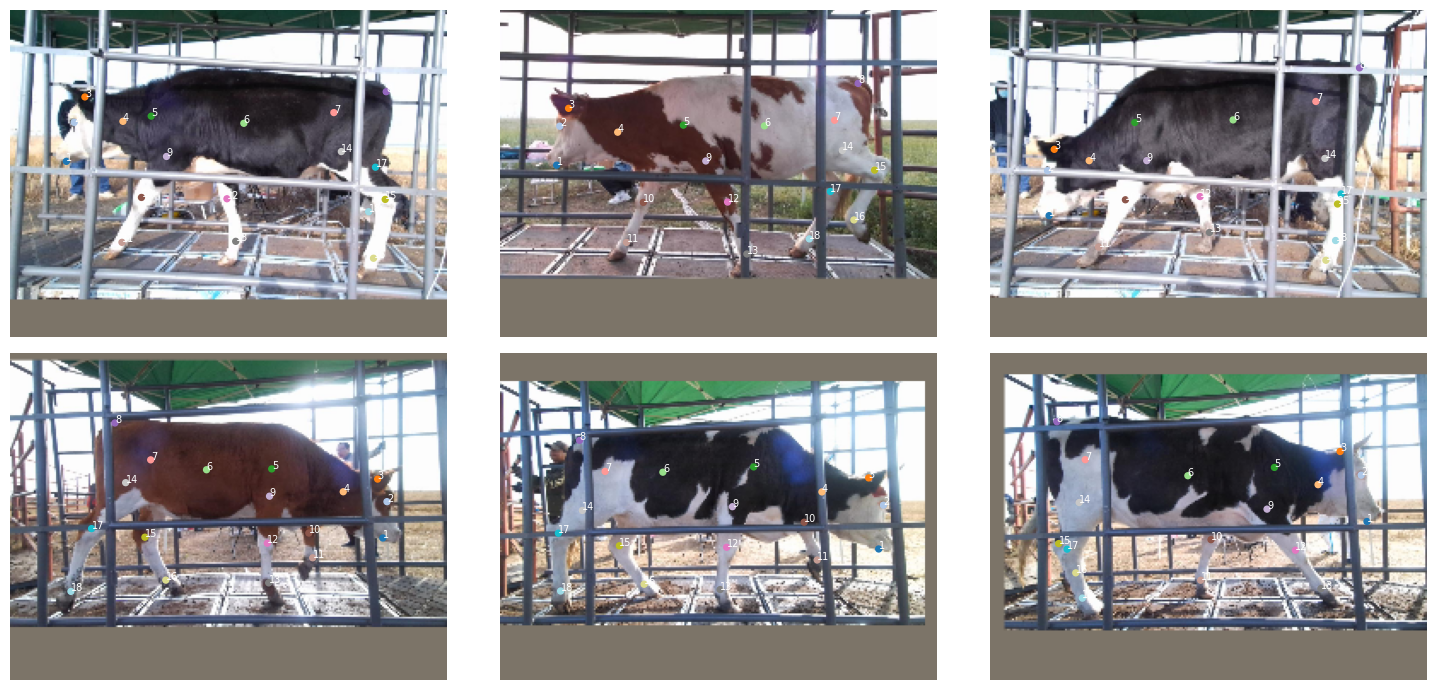

,index,keypoint
0,1,mouth
1,2,eye
2,3,ear
3,4,neck
4,5,shoulder
5,6,chest
6,7,hip
7,8,tail
8,9,elbow
9,10,l_fore_wrist


In [4]:
W,H=CFG['width'],CFG['height']; HW,HH=W//4,H//4
MEAN=np.array([.485,.456,.406],dtype=np.float32); STD=np.array([.229,.224,.225],dtype=np.float32)
def crop_geometry(box):
    x,y,w,h=box; cw=max(w,h*W/H)*CFG['crop_padding']; ch=cw*H/W
    return np.array([x+w/2-cw/2,y+h/2-ch/2,cw,ch],dtype=np.float32)
def make_crop(row):
    im=cv2.cvtColor(cv2.imread(row['path']),cv2.COLOR_BGR2RGB)
    x,y,cw,ch=crop_geometry(row['bbox'])
    matrix=np.array([[W/cw,0,-x*W/cw],[0,H/ch,-y*H/ch]],dtype=np.float32)
    crop=cv2.warpAffine(im,matrix,(W,H),flags=cv2.INTER_LINEAR,borderValue=(124,116,104))
    kp=np.array(row['keypoints'],dtype=np.float32); kp[:,:2]=kp[:,:2]@matrix[:,:2].T+matrix[:,2]
    return crop,kp
class CattleDataset(Dataset):
    def __init__(self,rows,augment=False):
        self.rows=rows; self.augment=augment; self.epoch=0
        self.cache=[make_crop(r) for r in tqdm(rows,desc='Cache crops')]
    def __len__(self): return len(self.rows)
    def __getitem__(self,index):
        image,kp=self.cache[index]; image=image.copy(); kp=kp.copy()
        if self.augment:
            rng=np.random.default_rng(CFG['seed']+self.epoch*100000+index)
            matrix=cv2.getRotationMatrix2D((W/2,H/2),float(rng.uniform(-20,20)),float(rng.uniform(.85,1.15))).astype(np.float32)
            matrix[:,2]+=rng.uniform(-.04,.04,2)*[W,H]
            image=cv2.warpAffine(image,matrix,(W,H),borderValue=(124,116,104))
            kp[:,:2]=kp[:,:2]@matrix[:,:2].T+matrix[:,2]
            image=np.clip(image.astype(np.float32)*rng.uniform(.8,1.2)+rng.uniform(-12,12),0,255)
        mask=(kp[:,2]>0)&(kp[:,0]>=0)&(kp[:,0]<W)&(kp[:,1]>=0)&(kp[:,1]<H)
        tensor=torch.from_numpy(((image.astype(np.float32)/255-MEAN)/STD).transpose(2,0,1).copy())
        return tensor,torch.from_numpy(kp[:,:2].copy()),torch.from_numpy(mask.astype(np.float32)),index
train_ds=CattleDataset(records['train'],augment=True); val_ds=CattleDataset(records['val'])
# Test crops are constructed only after checkpoint selection.
fig,axes=plt.subplots(2,3,figsize=(15,7))
for ax,(image,kp) in zip(axes.flat,train_ds.cache[:6]):
    ax.imshow(image); m=kp[:,2]>0
    ax.scatter(kp[m,0],kp[m,1],c=np.arange(K)[m],cmap='tab20',s=18)
    for j in np.flatnonzero(m): ax.text(kp[j,0],kp[j,1],str(j+1),fontsize=7,color='white')
    ax.axis('off')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'index':np.arange(1,K+1),'keypoint':NAMES}))

## 5. Model, supervision and metrics

ResNet-18 starts with ImageNet weights; three learned upsampling stages output 18 independent 64×48 heatmaps. Spatial cross-entropy matches Gaussian target distributions without overwhelming keypoint foreground with background pixels. Warm up the decoder for four epochs, then fine-tune the backbone at one tenth the decoder learning rate. Backbone batch statistics stay frozen during warm-up.

Select checkpoints by **validation PCK@0.05**: Euclidean joint error divided by the original box diagonal. Also report PCK@0.10, mean normalized error (NME), and normalized area under the PCK curve on [0, 0.20]. Higher PCK/AUC and lower NME are better. These metrics are not OKS AP and must not be compared numerically with the paper's AP tables. Heatmap peaks are not calibrated visibility probabilities.

In [5]:
class CattlePose(nn.Module):
    def __init__(self,pretrained=True):
        super().__init__()
        net=resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
        self.backbone=nn.Sequential(*list(net.children())[:-2]); layers=[]
        for cin,cout in [(512,128),(128,64),(64,32)]:
            layers.extend([nn.ConvTranspose2d(cin,cout,4,2,1,bias=False),nn.BatchNorm2d(cout),nn.ReLU(inplace=True)])
        self.decoder=nn.Sequential(*layers,nn.Conv2d(32,K,1))
    def forward(self,x): return self.decoder(self.backbone(x))
def heatmap_loss(logits,points,mask):
    yy,xx=torch.meshgrid(torch.arange(HH,device=logits.device),torch.arange(HW,device=logits.device),indexing='ij')
    center=(points+.5)/4-.5
    target=torch.exp(-((xx[None,None]-center[:,:,0,None,None])**2+
                       (yy[None,None]-center[:,:,1,None,None])**2)/(2*CFG['sigma']**2))
    target=target/target.sum((-2,-1),keepdim=True).clamp_min(1e-9)
    ce=-(target.flatten(2)*logits.float().flatten(2).log_softmax(-1)).sum(-1)
    return (ce*mask).sum()/mask.sum().clamp_min(1)
def decode(logits):
    # Argmax plus local quarter-pixel refinement, vectorized on GPU.
    hm=logits.float(); b,k,h,w=hm.shape; flat=hm.flatten(2).argmax(-1)
    x=flat%w; y=flat//w
    bi=torch.arange(b,device=hm.device)[:,None]; ji=torch.arange(k,device=hm.device)[None,:]
    dx=.25*torch.sign(hm[bi,ji,y,(x+1).clamp(max=w-1)]-hm[bi,ji,y,(x-1).clamp(min=0)])
    dy=.25*torch.sign(hm[bi,ji,(y+1).clamp(max=h-1),x]-hm[bi,ji,(y-1).clamp(min=0),x])
    xf=x.float()+dx*((x>0)&(x<w-1)); yf=y.float()+dy*((y>0)&(y<h-1))
    return (torch.stack((xf,yf),-1)+.5)*4-.5
def original_coordinates(points,rows):
    geo=np.array([crop_geometry(r['bbox']) for r in rows])
    return points*(geo[:,None,2:]/np.array([W,H]))+geo[:,None,:2]
def error_arrays(pred,rows):
    truth=np.array([r['keypoints'] for r in rows]); boxes=np.array([r['bbox'] for r in rows])
    errors=np.linalg.norm(pred-truth[:,:,:2],axis=-1)/np.linalg.norm(boxes[:,2:],axis=-1)[:,None]
    return errors,truth[:,:,2]
def summarize(errors,mask):
    e=errors[mask]
    if not len(e): return dict(count=0,PCK05=np.nan,PCK10=np.nan,NME=np.nan,AUC020=np.nan)
    return dict(count=len(e),PCK05=float((e<=.05).mean()),PCK10=float((e<=.10).mean()),
                NME=float(e.mean()),AUC020=float(np.maximum(1-e/.2,0).mean()))
@torch.no_grad()
def predict(model,dataset):
    loader=DataLoader(dataset,batch_size=CFG['batch_size'],shuffle=False,num_workers=0)
    model.eval(); predictions=[]; losses=[]
    for images,points,mask,indices in loader:
        images,points,mask=images.to(DEVICE),points.to(DEVICE),mask.to(DEVICE)
        logits=model(images); losses.append((heatmap_loss(logits,points,mask).item(),float(mask.sum())))
        predictions.append(decode(logits).cpu().numpy())
    pred=original_coordinates(np.concatenate(predictions),dataset.rows)
    return pred,sum(v*n for v,n in losses)/sum(n for _,n in losses)

## 6. Train, monitor, pause and resume

Each epoch updates `history.csv`, `status.json`, `learning_curves.png`, and the atomic `last.pt` checkpoint. `best.pt` is selected on validation only. Training uses mixed precision and gradient clipping. Checkpoints retain model, optimizer, scheduler, scaler, RNG states and history. A configuration and split fingerprint prevents accidental incompatible resumes.

**Pause:** interrupt this cell or create a `PAUSE` file from another terminal, from the repository root:
```powershell
New-Item ml/runs/cattle_resnet18_p1A/PAUSE -ItemType File -Force
```
**Resume:** remove `PAUSE`, then rerun cells in order. An incomplete epoch is replayed from the last completed checkpoint; at most one epoch is lost. Deterministic per-sample augmentation and epoch shuffling reproduce that epoch. Never run two trainers in this directory. Checkpoints must be your own trusted local files.

Read `history.csv` or open `learning_curves.png` while training. Live batch progress and epoch summaries also appear below. Early stopping uses validation PCK@.05 with 20 epochs of patience.

In [ ]:
def atomic_json(path,value):
    tmp=path.with_suffix(path.suffix+'.tmp'); tmp.write_text(json.dumps(value,indent=2)); tmp.replace(path)
def atomic_save(path,value):
    tmp=path.with_suffix(path.suffix+'.tmp'); torch.save(value,tmp); tmp.replace(path)
def plot_history(history,show=False):
    if not history: return
    frame=pd.DataFrame(history); fig,ax=plt.subplots(1,2,figsize=(11,3.5))
    ax[0].plot(frame.epoch,frame.train_loss,label='train'); ax[0].plot(frame.epoch,frame.val_loss,label='validation')
    ax[0].set(xlabel='Completed epoch',ylabel='Spatial cross entropy'); ax[0].legend()
    ax[1].plot(frame.epoch,frame.PCK05,label='PCK@.05'); ax[1].plot(frame.epoch,frame.PCK10,label='PCK@.10')
    ax[1].set(xlabel='Completed epoch',ylabel='Validation PCK',ylim=(0,1)); ax[1].legend()
    fig.tight_layout(); fig.savefig(RUN/'learning_curves.png',dpi=130)
    if show: plt.show()
    plt.close(fig)
def train():
    if (RUN/'PAUSE').exists():
        print('Paused: remove',RUN/'PAUSE','and rerun.'); return False
    signature=dict(config=CFG,source_commit=COMMIT,split_hash=SPLIT_HASH)
    config_path=RUN/'config.json'
    if config_path.exists(): assert json.loads(config_path.read_text())==signature, 'Configuration changed: use a new run directory.'
    else: atomic_json(config_path,signature)
    last_path=RUN/'last.pt'
    model=CattlePose(pretrained=CFG['pretrained'] and not last_path.exists()).to(DEVICE)
    optimizer=torch.optim.AdamW([{'params':model.backbone.parameters(),'lr':CFG['lr']*.1},
                                 {'params':model.decoder.parameters(),'lr':CFG['lr']}],weight_decay=CFG['weight_decay'])
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=CFG['epochs'],eta_min=1e-6)
    scaler=torch.cuda.amp.GradScaler(enabled=DEVICE.type=='cuda')
    history=[]; start=0; best=-1.; bad=0
    def checkpoint(epoch):
        return dict(model=model.state_dict(),optimizer=optimizer.state_dict(),scheduler=scheduler.state_dict(),
                    scaler=scaler.state_dict(),epoch=epoch,best=best,bad=bad,history=history,signature=signature,
                    torch_rng=torch.get_rng_state(),numpy_rng=np.random.get_state(),python_rng=random.getstate(),
                    cuda_rng=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else None)
    if last_path.exists():
        state=torch.load(last_path,map_location='cpu')
        assert state['signature']==signature
        model.load_state_dict(state['model']); optimizer.load_state_dict(state['optimizer'])
        scheduler.load_state_dict(state['scheduler']); scaler.load_state_dict(state['scaler'])
        start=state['epoch']+1; best=state['best']; bad=state['bad']; history=state['history']
        torch.set_rng_state(state['torch_rng']); np.random.set_state(state['numpy_rng']); random.setstate(state['python_rng'])
        if DEVICE.type=='cuda' and state['cuda_rng'] is not None: torch.cuda.set_rng_state_all(state['cuda_rng'])
        print(f'Resuming after epoch {start}; best validation PCK05={best:.4f}')
    else: atomic_save(last_path,checkpoint(-1))
    atomic_json(RUN/'environment.json',ENV)
    if history: pd.DataFrame(history).to_csv(RUN/'history.csv',index=False)
    try:
        for epoch in range(start,CFG['epochs']):
            if bad>=CFG['patience']: break
            if (RUN/'PAUSE').exists(): raise KeyboardInterrupt
            started=time.perf_counter(); train_ds.epoch=epoch; model.train(); frozen=epoch<CFG['freeze_epochs']
            for parameter in model.backbone.parameters(): parameter.requires_grad_(not frozen)
            if frozen: model.backbone.eval()
            generator=torch.Generator().manual_seed(CFG['seed']+epoch)
            loader=DataLoader(train_ds,batch_size=CFG['batch_size'],shuffle=True,generator=generator,num_workers=0,pin_memory=DEVICE.type=='cuda')
            total=0.; count=0.
            bar=tqdm(loader,desc=f"Epoch {epoch+1}/{CFG['epochs']}",leave=False)
            for images,points,mask,_ in bar:
                if (RUN/'PAUSE').exists(): raise KeyboardInterrupt
                images,points,mask=images.to(DEVICE),points.to(DEVICE),mask.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type=DEVICE.type,enabled=DEVICE.type=='cuda'):
                    loss=heatmap_loss(model(images),points,mask)
                assert torch.isfinite(loss), 'Nonfinite training loss'
                scaler.scale(loss).backward(); scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(),1.)
                scaler.step(optimizer); scaler.update()
                number=float(mask.sum()); total+=loss.item()*number; count+=number
                bar.set_postfix(loss=f'{total/max(count,1):.3f}')
            val_pred,val_loss=predict(model,val_ds)
            errors,visibility=error_arrays(val_pred,records['val']); metrics=summarize(errors,visibility>0)
            score=metrics['PCK05']; improved=score>best+1e-5
            if improved: best=score; bad=0
            else: bad+=1
            scheduler.step()
            row=dict(epoch=epoch+1,train_loss=total/count,val_loss=val_loss,**metrics,
                     seconds=time.perf_counter()-started,lr=optimizer.param_groups[1]['lr'])
            history.append(row); atomic_save(last_path,checkpoint(epoch))
            if improved: atomic_save(RUN/'best.pt',checkpoint(epoch))
            pd.DataFrame(history).to_csv(RUN/'history.csv',index=False)
            atomic_json(RUN/'status.json',dict(state='training',best_val_PCK05=best,patience_used=bad,**row))
            plot_history(history)
            print(f"Epoch {epoch+1:3d} | train {total/count:.3f} | val {val_loss:.3f} | PCK05 {score:.3%} | PCK10 {metrics['PCK10']:.3%} | {row['seconds']:.1f}s",flush=True)
        atomic_json(RUN/'status.json',dict(state='complete',completed_epoch=len(history),best_val_PCK05=best,
                                         reason='early stopping' if bad>=CFG['patience'] else 'epoch budget'))
        plot_history(history,show=True); return True
    except KeyboardInterrupt:
        atomic_json(RUN/'status.json',dict(state='paused',completed_epoch=len(history),best_val_PCK05=best))
        print('Paused safely after completed epoch',len(history),'; incomplete epoch will be replayed.'); return False
TRAINING_COMPLETE=train()

## 7. Held-out evaluation and train-only baseline

Load the checkpoint selected by validation, then evaluate test. Fit a constant mean-shape baseline on training labels normalized to each bounding box. Report all labeled, visible and occluded joints, plus per-joint metrics.

PCK confidence intervals use 1,000 bootstrap resamples of whole test images, preserving joint correlations within an image. They describe sampling variation within this test set, not uncertainty across farms or training seeds. Predictions are cached against the selected checkpoint hash. Never select a checkpoint using these test results.

In [ ]:
assert TRAINING_COMPLETE, 'Training paused: resume before final test evaluation.'
state=torch.load(RUN/'best.pt',map_location='cpu')
model=CattlePose(pretrained=False).to(DEVICE); model.load_state_dict(state['model']); model.eval()
checkpoint_hash=hashlib.sha256((RUN/'best.pt').read_bytes()).hexdigest(); cache_path=RUN/'test_predictions.npz'
if cache_path.exists():
    cached=np.load(cache_path)
    assert str(cached['checkpoint_hash'])==checkpoint_hash, 'Checkpoint changed: use a new evaluation directory.'
    test_pred=cached['predictions']
else:
    test_ds=CattleDataset(records['test']); test_pred,_=predict(model,test_ds)
    np.savez_compressed(cache_path,predictions=test_pred,checkpoint_hash=checkpoint_hash)
errors,visibility=error_arrays(test_pred,records['test'])
train_kp=np.array([r['keypoints'] for r in records['train']]); train_boxes=np.array([r['bbox'] for r in records['train']])
normalized=(train_kp[:,:,:2]-train_boxes[:,None,:2])/train_boxes[:,None,2:]
normalized[train_kp[:,:,2]==0]=np.nan; mean_shape=np.nanmean(normalized,axis=0)
assert np.isfinite(mean_shape).all(), 'A joint has no training labels.'
test_boxes=np.array([r['bbox'] for r in records['test']])
baseline_pred=mean_shape[None]*test_boxes[:,None,2:]+test_boxes[:,None,:2]
baseline_errors,_=error_arrays(baseline_pred,records['test']); summary=[]
for name,e in [('ResNet18 heatmaps',errors),('Train mean shape',baseline_errors)]:
    for subset,mask in [('all labeled',visibility>0),('visible',visibility==2),('occluded',visibility==1)]:
        summary.append(dict(model=name,subset=subset,**summarize(e,mask)))
summary=pd.DataFrame(summary); display(summary.round(4)); summary.to_csv(RUN/'test_metrics.csv',index=False)
per_joint=pd.DataFrame([dict(keypoint=name,**summarize(errors[:,j],visibility[:,j]>0)) for j,name in enumerate(NAMES)])
display(per_joint.round(4)); per_joint.to_csv(RUN/'per_joint_metrics.csv',index=False)
rng=np.random.default_rng(CFG['seed']); boots=[]
for _ in range(1000):
    indices=rng.integers(0,len(errors),len(errors)); boots.append(summarize(errors[indices],visibility[indices]>0)['PCK05'])
ci=np.quantile(boots,[.025,.975])
report=dict(checkpoint_epoch=state['epoch']+1,checkpoint_sha256=checkpoint_hash,validation_PCK05=state['best'],
            test_PCK05=summarize(errors,visibility>0)['PCK05'],test_PCK05_image_bootstrap_CI95=ci.tolist(),
            protocol='p1A with train/val filename repair; ground-truth boxes; bbox-diagonal PCK',
            source=provenance,split_hash=SPLIT_HASH,config=CFG)
atomic_json(RUN/'evaluation.json',report)
print(f"Selected epoch: {state['epoch']+1}; test PCK05 image-bootstrap 95% CI: [{ci[0]:.3%}, {ci[1]:.3%}]")

## 8. Performance curves and qualitative output

Green crosses are labels; red points are predictions. Show a fixed random test sample and the six largest mean errors. The network latency benchmark excludes detection, image loading, cropping, and decoding; it is not end-to-end latency.

In [ ]:
fig,axes=plt.subplots(1,3,figsize=(18,5)); thresholds=np.linspace(0,.2,101)
for name,e in [('ResNet18',errors),('Mean shape',baseline_errors)]:
    axes[0].plot(thresholds,[(e[visibility>0]<=t).mean() for t in thresholds],label=name)
axes[0].set(xlabel='Error / original bbox diagonal',ylabel='PCK',ylim=(0,1)); axes[0].legend(); axes[0].grid(alpha=.25)
axes[1].barh(per_joint.keypoint,per_joint.PCK05); axes[1].set(xlabel='Test PCK@.05',xlim=(0,1)); axes[1].invert_yaxis()
for v,label in [(2,'Visible'),(1,'Occluded')]:
    e=errors[visibility==v]
    if len(e): axes[2].hist(e,bins=np.linspace(0,.4,30),alpha=.5,label=label,density=True)
axes[2].set(xlabel='Normalized error (display range 0 to .4)',ylabel='Density'); axes[2].legend()
plt.tight_layout(); plt.savefig(RUN/'test_performance.png',dpi=150); plt.show()
def show_predictions(indices,title,filename):
    fig,axes=plt.subplots(2,3,figsize=(15,8))
    for ax,index in zip(axes.flat,indices):
        row=records['test'][int(index)]; image,kp=make_crop(row); geo=crop_geometry(row['bbox'])
        pred=(test_pred[index]-geo[:2])/geo[2:]*[W,H]; m=kp[:,2]>0
        ax.imshow(image); ax.scatter(kp[m,0],kp[m,1],c='lime',marker='x',s=25,label='Label')
        ax.scatter(pred[m,0],pred[m,1],c='red',s=12,label='Prediction')
        for j in np.flatnonzero(m): ax.plot([kp[j,0],pred[j,0]],[kp[j,1],pred[j,1]],color='yellow',alpha=.5,lw=.6)
        ax.set_title(f"Image {row['image_id']} | NME {errors[index,m].mean():.3f}"); ax.axis('off')
    axes.flat[0].legend(loc='lower left',fontsize=8); fig.suptitle(title); fig.tight_layout()
    fig.savefig(RUN/filename,dpi=140); plt.show()
show_predictions(np.random.default_rng(CFG['seed']).choice(len(errors),6,replace=False),'Fixed random test examples','test_examples.png')
mean_error=np.nanmean(np.where(visibility>0,errors,np.nan),axis=1)
show_predictions(np.argsort(mean_error)[-6:][::-1],'Six largest test errors','test_failures.png')
@torch.no_grad()
def benchmark():
    sample=torch.randn(CFG['batch_size'],3,H,W,device=DEVICE)
    for _ in range(10): model(sample)
    if DEVICE.type=='cuda': torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    timings=[]
    for _ in range(30):
        begin=time.perf_counter(); model(sample)
        if DEVICE.type=='cuda': torch.cuda.synchronize()
        timings.append(time.perf_counter()-begin)
    return dict(device=str(DEVICE),batch_size=CFG['batch_size'],crop_network_ms_per_image=1000*np.mean(timings)/CFG['batch_size'],
                crop_network_images_per_second=CFG['batch_size']/np.mean(timings),parameters=sum(p.numel() for p in model.parameters()),
                peak_cuda_MB=torch.cuda.max_memory_allocated()/1024**2 if DEVICE.type=='cuda' else None)
latency=benchmark(); atomic_json(RUN/'benchmark.json',latency); display(pd.DataFrame([latency]))

## 9. Inference on a new image and supplied cattle box

Return original-image coordinates in the documented joint order. No keypoint labels are needed. This model does not infer visibility, recognize cattle identities, or diagnose health. Accuracy here does not establish generalization to drone views.

Further work: independently identified farms/videos/animals, multiple training seeds, untouched source-group folds, and detector-plus-pose evaluation. Tune on validation only; the p1A test set has been consulted after this run.

In [ ]:
@torch.no_grad()
def infer_cattle(image_path,bbox):
    path=Path(image_path)
    with Image.open(path) as im: iw,ih=im.size
    x,y,w,h=map(float,bbox)
    assert x>=0 and y>=0 and w>0 and h>0 and x+w<=iw and y+h<=ih
    row=dict(path=str(path),bbox=[x,y,w,h],keypoints=np.zeros((K,3)).tolist()); crop,_=make_crop(row)
    tensor=torch.from_numpy(((crop.astype(np.float32)/255-MEAN)/STD).transpose(2,0,1).copy())[None].to(DEVICE)
    prediction=original_coordinates(decode(model(tensor)).cpu().numpy(),[row])[0]
    return pd.DataFrame({'keypoint':NAMES,'x':prediction[:,0],'y':prediction[:,1]})
# infer_cattle('path/to/cow.jpg', [100, 120, 600, 420])
print('Artifacts:',RUN)

## 10. SimCC with stronger training variation — separate experiment

The preceding heatmap experiment is preserved. This section is self-contained: **restart the Python 3.11 kernel and run section 10 onward** to train only SimCC. It reads the already downloaded cattle data, recreates the same repaired p1A split, and writes exclusively to `ml/runs/cattle_simcc_r18_384_p1A/`. Existing heatmap checkpoints and reports are read only for comparison.

SimCC predicts independent distributions over x and y coordinate bins for every joint. This implementation uses the same ImageNet-pretrained ResNet-18 backbone, two spatial upsampling stages, and shared linear coordinate classifiers applied to per-joint spatial features. At a split ratio of 2, coordinate bins are spaced 0.5 input pixels apart. This is a compact SimCC-style implementation, not a reproduction of RTMPose or the reference paper's full benchmark.

**Changes:** 384×288 crops (width×height), 300-epoch maximum, learning-rate warm-up and cosine decay, stronger augmentation, and a longer early-stopping window. These changes form a combined recipe; the comparison does not isolate the contribution of the head alone. No extra cattle data or animal-pose pretrained weights are introduced.

Reference: Li et al., *SimCC: A Simple Coordinate Classification Perspective for Human Pose Estimation*, ECCV 2022. [Paper](https://arxiv.org/abs/2107.03332), [official implementation](https://github.com/leeyegy/SimCC). Independent implementation here uses existing PyTorch/torchvision, without MMPose/MMCV or new package installs.

### 10.1 Configuration and imports

Start training explicitly by running the cell in **10.6**. Configuration/preview cells do not train a model. Defaults target the 6 GB RTX 3060; actual memory use is logged during training. If memory is insufficient, lower `batch_size` before the first run; set `accumulation_steps=2` to retain an effective batch of 16 with batch size 8. Use a new run directory when changing settings.

In [6]:
from pathlib import Path as SCPath
import os as sc_os
import sys as sc_sys
import json as sc_json
import time as sc_time
import math as sc_math
import copy as sc_copy
import random as sc_random
import hashlib as sc_hashlib
from collections import Counter as SCCounter
import numpy as sc_np
import pandas as sc_pd
# Preload the renderer before torch/OpenCV for this Windows environment.
from matplotlib.backends.backend_agg import FigureCanvasAgg as SCFigureCanvasAgg
import matplotlib.pyplot as sc_plt
from PIL import Image as SCImage
import cv2 as sc_cv2
import torch as sc_torch
from torch import nn as sc_nn
from torch.nn import functional as sc_F
from torch.utils.data import Dataset as SCDataset, DataLoader as SCDataLoader
from torchvision.models import resnet18 as sc_resnet18, ResNet18_Weights as SCResNet18Weights
from tqdm.auto import tqdm as sc_tqdm
from IPython.display import display as sc_display

SC_ROOT=SCPath.cwd().resolve()
if SC_ROOT.name=='ml': SC_ROOT=SC_ROOT.parent
assert (SC_ROOT/'ml').is_dir(), 'Open the notebook from the repository root or ml directory.'
SC_CFG=dict(seed=3407,fold='p1A',width=384,height=288,batch_size=16,
            accumulation_steps=1,epochs=300,min_epochs=200,patience=70,
            lr=0.0005,backbone_lr_ratio=0.1,weight_decay=0.0001,
            warmup_epochs=5,freeze_epochs=5,min_lr_ratio=0.01,
            split_ratio=2.0,target_sigma_px=3.0,crop_padding=1.25,
            pretrained=True,plot_every=5,augmentation_taper_start=150,
            augmentation_taper_end=250,rotation_degrees=30.0,
            scale_min=0.75,scale_max=1.30,translation_fraction=0.10,
            min_retained_fraction=0.65,blur_probability=0.25,
            motion_blur_probability=0.12,shadow_probability=0.35,
            noise_probability=0.35,occlusion_probability=0.30,
            grayscale_probability=0.05)
SC_COMMIT='d2fbc81e6181751f2e65eb6e393b10a9c7e16dfe'
SC_DATA=SC_ROOT/'ml/data/reference'
SC_CATTLE=SC_DATA/'data_process/cattle'
SC_BASELINE=SC_ROOT/'ml/runs/cattle_resnet18_p1A'
SC_RUN=SC_ROOT/'ml/runs/cattle_simcc_r18_384_p1A'
assert SC_RUN.resolve()!=SC_BASELINE.resolve()
SC_DEVICE=sc_torch.device('cuda' if sc_torch.cuda.is_available() else 'cpu')
SC_NAMES=['mouth','eye','ear','neck','shoulder','chest','hip','tail','elbow',
          'l_fore_wrist','l_fore_foot','r_fore_wrist','r_fore_foot','hind_knee',
          'l_hind_hock','l_hind_foot','r_hind_hock','r_hind_foot']
SC_K=len(SC_NAMES); SC_W=SC_CFG['width']; SC_H=SC_CFG['height']
assert SC_W%32==0 and SC_H%32==0
assert 0<SC_CFG['min_epochs']<=SC_CFG['epochs']
assert SC_CFG['batch_size']>0 and SC_CFG['accumulation_steps']>0
sc_torch.set_num_threads(min(4,sc_os.cpu_count() or 1))
sc_cv2.setNumThreads(1)
sc_torch.backends.cudnn.benchmark=False
sc_torch.backends.cudnn.deterministic=True
SC_MEAN=sc_np.array([.485,.456,.406],dtype=sc_np.float32)
SC_STD=sc_np.array([.229,.224,.225],dtype=sc_np.float32)
def sc_seed_all():
    sc_random.seed(SC_CFG['seed']); sc_np.random.seed(SC_CFG['seed'])
    sc_torch.manual_seed(SC_CFG['seed'])
    if SC_DEVICE.type=='cuda': sc_torch.cuda.manual_seed_all(SC_CFG['seed'])
def sc_atomic_json(path,value):
    temp=path.with_suffix(path.suffix+'.tmp')
    temp.write_text(sc_json.dumps(value,indent=2),encoding='utf-8'); temp.replace(path)
def sc_atomic_save(path,value):
    temp=path.with_suffix(path.suffix+'.tmp'); sc_torch.save(value,temp); temp.replace(path)
SC_ENV=dict(python=sc_sys.version,torch=sc_torch.__version__,numpy=sc_np.__version__,
            device=str(SC_DEVICE),gpu=sc_torch.cuda.get_device_name(0) if SC_DEVICE.type=='cuda' else None)
print(sc_json.dumps(SC_ENV,indent=2))
print('New run directory:',SC_RUN)
print('Budget:',SC_CFG['epochs'],'epochs; effective batch:',SC_CFG['batch_size']*SC_CFG['accumulation_steps'])

{
  "python": "3.11.4 (tags/v3.11.4:d2340ef, Jun  7 2023, 05:45:37) [MSC v.1934 64 bit (AMD64)]",
  "torch": "2.2.0+cu121",
  "numpy": "1.26.4",
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 3060 Laptop GPU"
}
New run directory: C:\Users\sam\Documents\GitHub\holycow\ml\runs\cattle_simcc_r18_384_p1A
Budget: 300 epochs; effective batch: 16


### 10.2 Reimport and validate the same partitions

Read the pinned cattle annotations and images directly; no earlier training cells are needed. Repeat category, visibility, coordinate, box, image, and file-integrity checks. Recreate the original filename-group repair, then require the same split fingerprint as the saved heatmap experiment when available. Animal/video independence remains unverified. Validation is unaugmented, and test is used only after selecting the SimCC checkpoint.

In [7]:
def sc_load_records():
    manifest_path=SC_DATA/'manifest.json'
    assert manifest_path.exists(), 'Reference data missing: run the original data import cells in sections 1–2 first.'
    manifest=sc_json.loads(manifest_path.read_text(encoding='utf-8'))
    assert manifest['sha']==SC_COMMIT and not manifest.get('truncated')
    blobs={item['path']:item['sha'] for item in manifest['tree'] if item['type']=='blob'}
    def verified_bytes(path,relative):
        content=path.read_bytes()
        digest=sc_hashlib.sha1(f'blob {len(content)}\0'.encode()+content).hexdigest()
        assert digest==blobs[relative], f'Upstream integrity mismatch: {relative}'
        return content
    partitions={}
    for split in ('train','val','test'):
        relative=f"data_process/cattle/annotations_p1/cattle_{SC_CFG['fold']}_{split}.json"
        coco=sc_json.loads(verified_bytes(SC_DATA/relative,relative))
        images={im['id']:im for im in coco['images']}
        assert len(images)==len(coco['images'])
        assert len({a['id'] for a in coco['annotations']})==len(coco['annotations'])
        cats={cat['id']:cat for cat in coco['categories']}; rows=[]
        for annotation in sc_tqdm(coco['annotations'],desc=f'Validate {split}'):
            assert annotation['image_id'] in images
            category=cats[annotation['category_id']]
            assert category['name'].lower()=='cattle' and category['keypoints']==SC_NAMES
            im=images[annotation['image_id']]; path=(SC_CATTLE/im['file_name']).resolve()
            assert path.is_relative_to(SC_CATTLE.resolve())
            content=verified_bytes(path,'data_process/cattle/'+im['file_name'])
            with SCImage.open(path) as image:
                image.load(); assert image.size==(im['width'],im['height'])
            kp=sc_np.asarray(annotation['keypoints'],dtype=sc_np.float32).reshape(SC_K,3)
            bbox=sc_np.asarray(annotation['bbox'],dtype=sc_np.float32)
            assert sc_np.isfinite(kp).all() and sc_np.isfinite(bbox).all()
            assert set(kp[:,2]).issubset({0.,1.,2.})
            mask=kp[:,2]>0
            assert mask.any() and int(mask.sum())==annotation['num_keypoints']
            assert (kp[mask,:2]>=0).all()
            assert (kp[mask,0]<=im['width']).all() and (kp[mask,1]<=im['height']).all()
            x,y,w,h=bbox
            assert x>=0 and y>=0 and w>0 and h>0 and x+w<=im['width']+1 and y+h<=im['height']+1
            original=im.get('extra',{}).get('name',SCPath(im['file_name']).name.split('.rf.')[0])
            rows.append(dict(image_id=im['id'],annotation_id=annotation['id'],path=str(path),
                             file_name=im['file_name'],group=im['batch_id'],original=original.lower(),
                             sha256=sc_hashlib.sha256(content).hexdigest(),bbox=bbox.tolist(),keypoints=kp.tolist()))
        partitions[split]=rows
    shared={r['original'] for r in partitions['train']} & {r['original'] for r in partitions['val']}
    moved=[r for r in partitions['train'] if r['original'] in shared]
    partitions['train']=[r for r in partitions['train'] if r['original'] not in shared]
    partitions['val'].extend(moved)
    for i,a in enumerate(('train','val','test')):
        for b in ('train','val','test')[i+1:]:
            for key in ('sha256','original'):
                assert not ({r[key] for r in partitions[a]} & {r[key] for r in partitions[b]}), f'{key} leakage: {a}/{b}'
    assert {r['group'] for r in partitions['test']}=={'A'}
    assert not ({r['group'] for r in partitions['train']+partitions['val']} & {'A'})
    split_manifest={s:[{k:v for k,v in r.items() if k not in ('path','keypoints')} for r in rows]
                    for s,rows in partitions.items()}
    fingerprint=sc_hashlib.sha256(sc_json.dumps(split_manifest,sort_keys=True).encode()).hexdigest()
    old_manifest=SC_BASELINE/'split_manifest.json'
    if old_manifest.exists():
        old=sc_json.loads(old_manifest.read_text(encoding='utf-8'))
        assert old==split_manifest, 'Baseline partitions differ; stop before comparing runs.'
    print('Same split repair:',len(shared),'filename groups;',len(moved),'moved records')
    return partitions,split_manifest,fingerprint
sc_records,sc_split_manifest,SC_SPLIT_HASH=sc_load_records()
SC_RUN.mkdir(parents=True,exist_ok=True)
SC_SIGNATURE=dict(implementation='simcc-r18-v1',config=SC_CFG,source_commit=SC_COMMIT,split_hash=SC_SPLIT_HASH)
if (SC_RUN/'config.json').exists():
    assert sc_json.loads((SC_RUN/'config.json').read_text())==SC_SIGNATURE, 'Use a new run folder for changed settings.'
sc_atomic_json(SC_RUN/'config.json',SC_SIGNATURE)
sc_atomic_json(SC_RUN/'split_manifest.json',sc_split_manifest)
sc_atomic_json(SC_RUN/'environment.json',SC_ENV)
sc_audit=sc_pd.DataFrame([dict(split=s,images=len({r['image_id'] for r in rows}),animals=len(rows),
                              labeled=sum(sc_np.count_nonzero(sc_np.array(r['keypoints'])[:,2]) for r in rows),
                              visible=sum(sc_np.count_nonzero(sc_np.array(r['keypoints'])[:,2]==2) for r in rows),
                              groups=dict(SCCounter(r['group'] for r in rows))) for s,rows in sc_records.items()])
sc_audit.to_csv(SC_RUN/'data_audit.csv',index=False)
sc_display(sc_audit); print('Split fingerprint:',SC_SPLIT_HASH)

Validate train:   0%|          | 0/614 [00:00<?, ?it/s]

Validate val:   0%|          | 0/68 [00:00<?, ?it/s]

Validate test:   0%|          | 0/206 [00:00<?, ?it/s]

Same split repair: 9 filename groups; 10 moved records


,split,images,animals,labeled,visible,groups
0,train,604,604,10850,9946,"{'B': 354, 'C': 250}"
1,val,78,78,1404,1272,"{'B': 43, 'C': 35}"
2,test,206,206,3708,3611,{'A': 206}


Split fingerprint: b67a99ada5d651ae6e8cf970c930ca4c11ea00efae7515f68d7779ce1e53dc8d


### 10.3 Stronger, reproducible training variation

Every training sample gets a deterministic transform keyed by seed, epoch and image index. Geometry uses up to ±30° rotation, 0.75–1.30 scale and ±10% translation, with identical coordinate transforms for image and joints. Retry transformations that would remove too many labeled joints. Photometric variation adds contrast/exposure/gamma, hue/saturation, smooth shadows, Gaussian or motion blur, noise, occasional grayscale, and small occluders. Occluded labeled joints remain supervised; points outside the image crop are masked.

Augmentation gradually tapers after epoch 150 to help final localization converge. No horizontal flip is used until the dataset's left/right conventions are verified. Validation/test use deterministic crops only. The preview below shows augmented **training** examples, including joint numbers, before you choose to train.

Cache SimCC crops:   0%|          | 0/604 [00:00<?, ?it/s]

Cache SimCC crops:   0%|          | 0/78 [00:00<?, ?it/s]

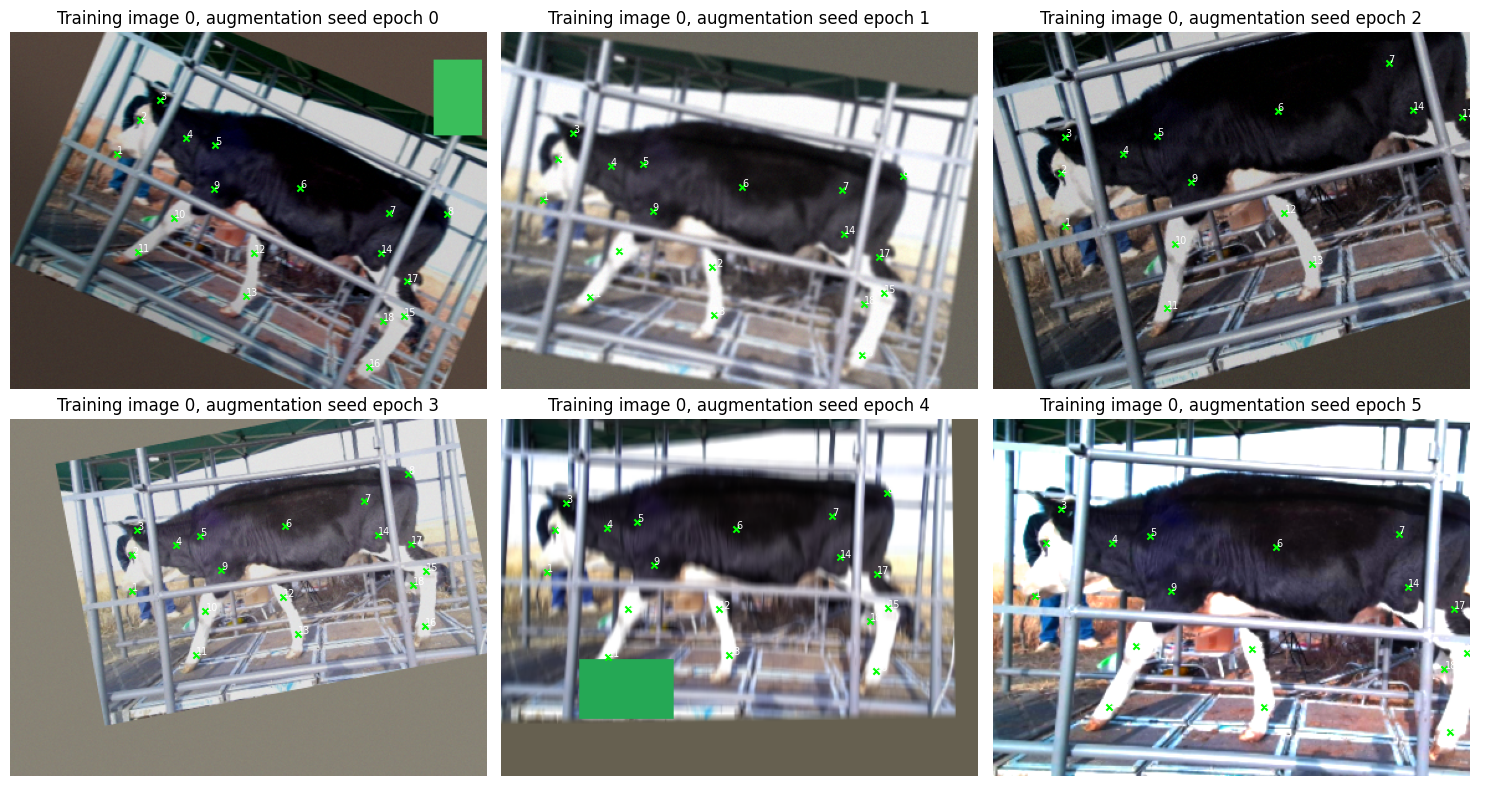

In [8]:
def sc_geometry(bbox):
    x,y,w,h=bbox
    cw=max(w,h*SC_W/SC_H)*SC_CFG['crop_padding']; ch=cw*SC_H/SC_W
    return sc_np.array([x+w/2-cw/2,y+h/2-ch/2,cw,ch],dtype=sc_np.float32)
def sc_crop(row):
    raw=sc_cv2.imread(row['path'])
    assert raw is not None, row['path']
    image=sc_cv2.cvtColor(raw,sc_cv2.COLOR_BGR2RGB)
    x,y,cw,ch=sc_geometry(row['bbox'])
    matrix=sc_np.array([[SC_W/cw,0,-x*SC_W/cw],[0,SC_H/ch,-y*SC_H/ch]],dtype=sc_np.float32)
    crop=sc_cv2.warpAffine(image,matrix,(SC_W,SC_H),flags=sc_cv2.INTER_LINEAR,borderValue=(124,116,104))
    kp=sc_np.array(row['keypoints'],dtype=sc_np.float32)
    kp[:,:2]=kp[:,:2]@matrix[:,:2].T+matrix[:,2]
    return crop,kp
def sc_valid_points(kp):
    return (kp[:,2]>0)&(kp[:,0]>=0)&(kp[:,0]<SC_W)&(kp[:,1]>=0)&(kp[:,1]<SC_H)
def sc_photometric(image,rng,strength):
    image=image.astype(sc_np.float32)/255.
    if rng.random()<.8:
        contrast=rng.uniform(1-.35*strength,1+.40*strength)
        image=(image-.5)*contrast+.5+rng.uniform(-.15,.15)*strength
    if rng.random()<.6:
        gamma=rng.uniform(1-.30*strength,1+.40*strength)
        image=sc_np.clip(image,0,1)**gamma
    image=sc_np.clip(image*255,0,255).astype(sc_np.uint8)
    if rng.random()<.7:
        hsv=sc_cv2.cvtColor(image,sc_cv2.COLOR_RGB2HSV).astype(sc_np.float32)
        hsv[:,:,0]=(hsv[:,:,0]+rng.uniform(-6,6)*strength)%180
        hsv[:,:,1]=sc_np.clip(hsv[:,:,1]*rng.uniform(1-.4*strength,1+.4*strength),0,255)
        image=sc_cv2.cvtColor(hsv.astype(sc_np.uint8),sc_cv2.COLOR_HSV2RGB)
    image=image.astype(sc_np.float32)
    if rng.random()<SC_CFG['shadow_probability']*strength:
        # Smooth half-plane shading rather than a sharp synthetic rectangle.
        yy,xx=sc_np.mgrid[0:SC_H,0:SC_W]
        theta=rng.uniform(0,2*sc_np.pi)
        distance=(xx/SC_W-.5)*sc_np.cos(theta)+(yy/SC_H-.5)*sc_np.sin(theta)+rng.uniform(-.3,.3)
        transition=1/(1+sc_np.exp(sc_np.clip(-distance*15,-30,30)))
        shading=1-rng.uniform(.2,.55)*strength*transition
        image*=shading[:,:,None]
    if rng.random()<SC_CFG['blur_probability']*strength:
        kernel=int(rng.choice([3,5])); image=sc_cv2.GaussianBlur(image,(kernel,kernel),rng.uniform(.4,1.5))
    if rng.random()<SC_CFG['motion_blur_probability']*strength:
        length=int(rng.choice([3,5,7])); kernel=sc_np.zeros((length,length),dtype=sc_np.float32)
        if rng.random()<.5: kernel[length//2,:]=1/length
        else: kernel[:,length//2]=1/length
        image=sc_cv2.filter2D(image,-1,kernel)
    if rng.random()<SC_CFG['noise_probability']*strength:
        image+=rng.normal(0,rng.uniform(1,7)*strength,image.shape).astype(sc_np.float32)
    image=sc_np.clip(image,0,255).astype(sc_np.uint8)
    if rng.random()<SC_CFG['grayscale_probability']*strength:
        gray=sc_cv2.cvtColor(image,sc_cv2.COLOR_RGB2GRAY); image=sc_np.repeat(gray[:,:,None],3,axis=2)
    if rng.random()<SC_CFG['occlusion_probability']*strength:
        rw=max(1,int(SC_W*rng.uniform(.08,.22))); rh=max(1,int(SC_H*rng.uniform(.08,.22)))
        x=int(rng.integers(0,SC_W-rw+1)); y=int(rng.integers(0,SC_H-rh+1))
        image[y:y+rh,x:x+rw]=rng.integers(30,220,3,dtype=sc_np.uint8)
    return image
class SCSimCCDataset(SCDataset):
    def __init__(self,rows,augment=False):
        self.rows=rows; self.augment=augment; self.epoch=0
        self.cache=[sc_crop(row) for row in sc_tqdm(rows,desc='Cache SimCC crops')]
    def __len__(self): return len(self.rows)
    def strength(self):
        start=SC_CFG['augmentation_taper_start']; end=SC_CFG['augmentation_taper_end']
        return float(sc_np.clip(1-.65*(self.epoch-start)/max(1,end-start),.35,1))
    def sample(self,index,epoch=None):
        image,kp=self.cache[index]; image=image.copy(); kp=kp.copy()
        if self.augment:
            ep=self.epoch if epoch is None else int(epoch)
            rng=sc_np.random.default_rng(sc_np.random.SeedSequence([SC_CFG['seed'],ep,int(index)]))
            start=SC_CFG['augmentation_taper_start']; end=SC_CFG['augmentation_taper_end']
            strength=float(sc_np.clip(1-.65*(ep-start)/max(1,end-start),.35,1))
            minimum=max(1,int(sc_np.ceil(sc_valid_points(kp).sum()*SC_CFG['min_retained_fraction'])))
            for _ in range(4):
                angle=rng.uniform(-1,1)*SC_CFG['rotation_degrees']*strength
                scale=rng.uniform(1+(SC_CFG['scale_min']-1)*strength,1+(SC_CFG['scale_max']-1)*strength)
                matrix=sc_cv2.getRotationMatrix2D((SC_W/2,SC_H/2),float(angle),float(scale)).astype(sc_np.float32)
                matrix[:,2]+=rng.uniform(-1,1,2)*SC_CFG['translation_fraction']*strength*[SC_W,SC_H]
                transformed=kp.copy(); transformed[:,:2]=kp[:,:2]@matrix[:,:2].T+matrix[:,2]
                if sc_valid_points(transformed).sum()>=minimum:
                    image=sc_cv2.warpAffine(image,matrix,(SC_W,SC_H),borderValue=(124,116,104))
                    kp=transformed; break
            image=sc_photometric(image,rng,strength)
        return image,kp,sc_valid_points(kp)
    def __getitem__(self,index):
        image,kp,mask=self.sample(index)
        tensor=sc_torch.from_numpy(((image.astype(sc_np.float32)/255-SC_MEAN)/SC_STD).transpose(2,0,1).copy())
        return tensor,sc_torch.from_numpy(kp[:,:2].copy()),sc_torch.from_numpy(mask.astype(sc_np.float32)),index
sc_train_ds=SCSimCCDataset(sc_records['train'],augment=True)
sc_val_ds=SCSimCCDataset(sc_records['val'])
sc_preview_fig,sc_preview_axes=sc_plt.subplots(2,3,figsize=(15,8))
for sc_ax,sc_epoch in zip(sc_preview_axes.flat,range(6)):
    sc_image,sc_kp,sc_mask=sc_train_ds.sample(0,epoch=sc_epoch)
    sc_ax.imshow(sc_image)
    sc_ax.scatter(sc_kp[sc_mask,0],sc_kp[sc_mask,1],c='lime',marker='x',s=20)
    for sc_j in sc_np.flatnonzero(sc_mask):
        sc_ax.text(sc_kp[sc_j,0],sc_kp[sc_j,1],str(sc_j+1),color='white',fontsize=7)
    sc_ax.set_title(f'Training image 0, augmentation seed epoch {sc_epoch}'); sc_ax.axis('off')
sc_preview_fig.tight_layout(); sc_preview_fig.savefig(SC_RUN/'augmentation_preview.png',dpi=130)
sc_plt.show(); sc_plt.close(sc_preview_fig)

### 10.4 SimCC model and loss

The backbone outputs stride-32 features. Two learned upsampling layers produce stride-8 spatial features, then one channel per joint. Flatten each joint's feature plane and apply x/y linear classifiers. Separate normalized Gaussian targets supervise the two axes with masked KL divergence. A bin at index `j` represents coordinate `j / split_ratio` pixels; encoding and decoding use the same convention. Argmax decoding avoids averaging between separate limb hypotheses. Unlike heatmaps, no quarter-pixel refinement is used.

Only ImageNet initialization is used: this experiment does not inherit the old cattle checkpoint. Visible and occluded labeled points carry equal weight. Coordinate distributions do not estimate visibility or provide calibrated confidence.

In [9]:
class SCSimCCPose(sc_nn.Module):
    def __init__(self,pretrained=True):
        super().__init__()
        net=sc_resnet18(weights=SCResNet18Weights.DEFAULT if pretrained else None)
        self.backbone=sc_nn.Sequential(*list(net.children())[:-2])
        self.spatial_head=sc_nn.Sequential(
            sc_nn.ConvTranspose2d(512,128,4,2,1,bias=False),sc_nn.BatchNorm2d(128),sc_nn.ReLU(inplace=True),
            sc_nn.ConvTranspose2d(128,64,4,2,1,bias=False),sc_nn.BatchNorm2d(64),sc_nn.ReLU(inplace=True),
            sc_nn.Conv2d(64,SC_K,1))
        features=(SC_W//8)*(SC_H//8)
        self.norm=sc_nn.LayerNorm(features)
        self.classifier_x=sc_nn.Linear(features,int(SC_W*SC_CFG['split_ratio']))
        self.classifier_y=sc_nn.Linear(features,int(SC_H*SC_CFG['split_ratio']))
        sc_nn.init.normal_(self.classifier_x.weight,std=.001); sc_nn.init.zeros_(self.classifier_x.bias)
        sc_nn.init.normal_(self.classifier_y.weight,std=.001); sc_nn.init.zeros_(self.classifier_y.bias)
    def forward(self,images):
        features=self.norm(self.spatial_head(self.backbone(images)).flatten(2))
        return self.classifier_x(features),self.classifier_y(features)
def sc_axis_target(coordinates,bins):
    grid=sc_torch.arange(bins,device=coordinates.device,dtype=sc_torch.float32)
    centers=coordinates.float()[...,None]*SC_CFG['split_ratio']
    sigma=SC_CFG['target_sigma_px']*SC_CFG['split_ratio']
    return (-.5*((grid-centers)/sigma)**2).softmax(-1)
def sc_simcc_loss(outputs,points,mask):
    lx,ly=outputs
    # Unlabeled/out-of-crop coordinates contribute neither targets nor gradients.
    safe=sc_torch.where(mask[...,None]>0,points,sc_torch.zeros_like(points))
    tx=sc_axis_target(safe[:,:,0],lx.shape[-1]); ty=sc_axis_target(safe[:,:,1],ly.shape[-1])
    loss_x=sc_F.kl_div(lx.float().log_softmax(-1),tx,reduction='none').sum(-1)
    loss_y=sc_F.kl_div(ly.float().log_softmax(-1),ty,reduction='none').sum(-1)
    return ((loss_x+loss_y)*mask).sum()/(2*mask.sum().clamp_min(1))
def sc_decode(outputs):
    lx,ly=outputs
    return sc_torch.stack((lx.argmax(-1),ly.argmax(-1)),dim=-1).float()/SC_CFG['split_ratio']
def sc_to_original(points,rows):
    geometry=sc_np.array([sc_geometry(r['bbox']) for r in rows])
    return points*(geometry[:,None,2:]/sc_np.array([SC_W,SC_H]))+geometry[:,None,:2]
def sc_errors(predictions,rows):
    truth=sc_np.array([r['keypoints'] for r in rows]); boxes=sc_np.array([r['bbox'] for r in rows])
    error=sc_np.linalg.norm(predictions-truth[:,:,:2],axis=-1)/sc_np.linalg.norm(boxes[:,2:],axis=-1)[:,None]
    return error,truth[:,:,2]
def sc_summary(errors,mask):
    selected=errors[mask]
    if not len(selected): return dict(count=0,PCK05=None,PCK10=None,NME=None,AUC020=None)
    return dict(count=len(selected),PCK05=float((selected<=.05).mean()),PCK10=float((selected<=.10).mean()),
                NME=float(selected.mean()),AUC020=float(sc_np.maximum(1-selected/.2,0).mean()))
class SCPauseRequested(Exception): pass
def sc_pause_check():
    if (SC_RUN/'PAUSE').exists(): raise SCPauseRequested()
@sc_torch.no_grad()
def sc_predict(pose_model,dataset,check_pause=False):
    loader=SCDataLoader(dataset,batch_size=SC_CFG['batch_size'],shuffle=False,num_workers=0,
                        pin_memory=SC_DEVICE.type=='cuda')
    pose_model.eval(); predictions=[]; total=0.; labeled=0.
    for images,points,mask,_ in loader:
        if check_pause: sc_pause_check()
        images,points,mask=images.to(SC_DEVICE),points.to(SC_DEVICE),mask.to(SC_DEVICE)
        # Full precision evaluation matches the baseline's evaluation precision.
        outputs=pose_model(images); number=float(mask.sum())
        total+=sc_simcc_loss(outputs,points,mask).item()*number; labeled+=number
        predictions.append(sc_decode(outputs).cpu().numpy())
    return sc_to_original(sc_np.concatenate(predictions),dataset.rows),total/max(labeled,1)

The following small CPU checks validate output dimensions, normalized targets, edge-coordinate decoding, masked gradients and crop-coordinate round trips before a training run. They use synthetic inputs and no downloaded weights or cattle training. These checks run only when you execute this cell.

In [10]:
def sc_check_implementation():
    points=sc_torch.tensor([[[0.,0.],[SC_W-.5,SC_H-.5],[SC_W/2,SC_H/2]]])
    mask=sc_torch.tensor([[1.,1.,0.]])
    tx=sc_axis_target(points[:,:,0],int(SC_W*SC_CFG['split_ratio']))
    ty=sc_axis_target(points[:,:,1],int(SC_H*SC_CFG['split_ratio']))
    assert sc_torch.allclose(tx.sum(-1),sc_torch.ones_like(mask),atol=1e-6)
    assert sc_torch.allclose(ty.sum(-1),sc_torch.ones_like(mask),atol=1e-6)
    lx=tx.clamp_min(1e-12).log().requires_grad_()
    ly=ty.clamp_min(1e-12).log().requires_grad_()
    decoded=sc_decode((lx,ly))
    assert sc_torch.max(sc_torch.abs(decoded-points)).item()<=1/SC_CFG['split_ratio']
    loss=sc_simcc_loss((lx,ly),points,mask); loss.backward()
    assert sc_torch.isfinite(loss) and sc_torch.isfinite(lx.grad).all() and sc_torch.isfinite(ly.grad).all()
    assert lx.grad[0,2].abs().sum().item()==0 and ly.grad[0,2].abs().sum().item()==0
    perturbed=points.clone(); perturbed[0,2]=sc_torch.tensor([-1000.,1000.])
    assert sc_torch.allclose(loss.detach(),sc_simcc_loss((lx,ly),perturbed,mask),atol=1e-7)
    sample_row=dict(bbox=[100.,50.,800.,500.]); geometry=sc_geometry(sample_row['bbox'])
    original=sc_np.array([[[150.,100.],[800.,450.]]])
    crop=(original-geometry[None,None,:2])/geometry[None,None,2:]*[SC_W,SC_H]
    assert sc_np.allclose(sc_to_original(crop,[sample_row]),original,atol=1e-4)
    with sc_torch.random.fork_rng(devices=[]):
        probe=SCSimCCPose(pretrained=False).cpu().eval()
        with sc_torch.no_grad():
            out_x,out_y=probe(sc_torch.zeros(2,3,SC_H,SC_W))
        assert out_x.shape==(2,SC_K,int(SC_W*SC_CFG['split_ratio']))
        assert out_y.shape==(2,SC_K,int(SC_H*SC_CFG['split_ratio']))
        assert sc_torch.isfinite(out_x).all() and sc_torch.isfinite(out_y).all()
    print('SimCC CPU smoke checks passed; no training performed.')
sc_check_implementation()

SimCC CPU smoke checks passed; no training performed.


### 10.5 Training engine: warm-up, longer budget, logging and resume

Warm up the new head with the backbone frozen for five epochs, then fine-tune the backbone at one tenth the head learning rate. Use AMP, gradient clipping, optional gradient accumulation, five-epoch LR warm-up and cosine decay. Early stopping starts only after 200 completed epochs, with 70-epoch patience on validation PCK@0.05. Select the best checkpoint solely by validation; no test labels are consulted.

`last.pt` contains the last completed epoch, optimizer/scheduler/scaler, RNG states, history, and the best model so far. Resume reconstructs `best.pt` from this authoritative state. New logs include losses, PCK, NME, LR, augmentation strength, epoch time and peak GPU allocation. Curves refresh every five epochs. A lock prevents concurrent trainers from writing the same folder.

All controls refer to the **new** run folder:
```powershell
# Read progress while the training cell is running:
Get-Content ml/runs/cattle_simcc_r18_384_p1A/status.json
Get-Content ml/runs/cattle_simcc_r18_384_p1A/history.csv -Tail 10
# Pause at a batch boundary (kernel interrupt also works):
New-Item ml/runs/cattle_simcc_r18_384_p1A/PAUSE -ItemType File -Force
# Resume: remove the marker, then rerun section 10 (or just the training cell in the same kernel):
Remove-Item -LiteralPath ml/runs/cattle_simcc_r18_384_p1A/PAUSE
```
An incomplete epoch is replayed with the same augmentation and shuffle seeds. Abrupt process termination may leave `TRAINING.lock`; remove that file only after verifying the earlier trainer is no longer running. Only load your own trusted local checkpoints.

In [11]:
def sc_plot_history(history,show=False):
    if not history: return
    frame=sc_pd.DataFrame(history); figure,axes=sc_plt.subplots(1,3,figsize=(15,4))
    axes[0].plot(frame.epoch,frame.train_loss,label='Augmented train')
    axes[0].plot(frame.epoch,frame.val_loss,label='Validation'); axes[0].legend()
    axes[0].set(xlabel='Epoch',ylabel='Mean axis KL divergence')
    axes[1].plot(frame.epoch,frame.PCK05,label='PCK@.05')
    axes[1].plot(frame.epoch,frame.PCK10,label='PCK@.10'); axes[1].legend()
    axes[1].set(xlabel='Epoch',ylabel='Validation PCK',ylim=(0,1))
    axes[2].plot(frame.epoch,frame.lr,label='Head LR'); axes[2].legend()
    axes[2].set(xlabel='Epoch',ylabel='Learning rate',yscale='log')
    figure.tight_layout(); figure.savefig(SC_RUN/'learning_curves.png',dpi=130)
    if show: sc_plt.show()
    sc_plt.close(figure)
def sc_lr_multiplier(epoch):
    warmup=SC_CFG['warmup_epochs']
    if epoch<warmup: return (epoch+1)/max(warmup,1)
    progress=min(1.,(epoch-warmup)/max(1,SC_CFG['epochs']-warmup))
    floor=SC_CFG['min_lr_ratio']
    return floor+(1-floor)*.5*(1+sc_math.cos(sc_math.pi*progress))
def sc_load_trusted(path):
    return sc_torch.load(path,map_location='cpu',weights_only=False)
def sc_fit():
    assert sc_json.loads((SC_RUN/'config.json').read_text())==SC_SIGNATURE, 'Configuration changed; use a new run directory.'
    sc_seed_all()
    last_path=SC_RUN/'last.pt'; resuming=last_path.exists()
    pose_model=SCSimCCPose(pretrained=SC_CFG['pretrained'] and not resuming).to(SC_DEVICE)
    backbone_parameters=list(pose_model.backbone.parameters())
    backbone_ids={id(p) for p in backbone_parameters}
    head_parameters=[p for p in pose_model.parameters() if id(p) not in backbone_ids]
    optimizer=sc_torch.optim.AdamW([
        dict(params=backbone_parameters,lr=SC_CFG['lr']*SC_CFG['backbone_lr_ratio']),
        dict(params=head_parameters,lr=SC_CFG['lr'])],weight_decay=SC_CFG['weight_decay'])
    scheduler=sc_torch.optim.lr_scheduler.LambdaLR(optimizer,sc_lr_multiplier)
    scaler=sc_torch.cuda.amp.GradScaler(enabled=SC_DEVICE.type=='cuda')
    history=[]; start=0; best_score=-1.; best_epoch=0; best_weights=None; best_metrics=None; bad_epochs=0
    def checkpoint(completed):
        return dict(signature=SC_SIGNATURE,completed_epoch=completed,model=pose_model.state_dict(),
                    optimizer=optimizer.state_dict(),scheduler=scheduler.state_dict(),scaler=scaler.state_dict(),
                    history=history,best_score=best_score,best_epoch=best_epoch,best_model=best_weights,
                    best_metrics=best_metrics,bad_epochs=bad_epochs,
                    python_rng=sc_random.getstate(),numpy_rng=sc_np.random.get_state(),
                    torch_rng=sc_torch.get_rng_state(),
                    cuda_rng=sc_torch.cuda.get_rng_state_all() if SC_DEVICE.type=='cuda' else None)
    def publish_best():
        if best_weights is not None:
            sc_atomic_save(SC_RUN/'best.pt',dict(signature=SC_SIGNATURE,model=best_weights,
                           completed_epoch=best_epoch,validation=best_metrics))
    if resuming:
        saved=sc_load_trusted(last_path)
        assert saved['signature']==SC_SIGNATURE, 'Resume signature mismatch.'
        pose_model.load_state_dict(saved['model']); optimizer.load_state_dict(saved['optimizer'])
        scheduler.load_state_dict(saved['scheduler']); scaler.load_state_dict(saved['scaler'])
        history=saved['history']; start=saved['completed_epoch']; best_score=saved['best_score']
        best_epoch=saved['best_epoch']; best_weights=saved['best_model']; best_metrics=saved['best_metrics']
        bad_epochs=saved['bad_epochs']
        sc_random.setstate(saved['python_rng']); sc_np.random.set_state(saved['numpy_rng'])
        sc_torch.set_rng_state(saved['torch_rng'])
        if SC_DEVICE.type=='cuda' and saved['cuda_rng'] is not None:
            sc_torch.cuda.set_rng_state_all(saved['cuda_rng'])
        del saved
        publish_best()
        if history: sc_pd.DataFrame(history).to_csv(SC_RUN/'history.csv',index=False)
        print(f'Resume after {start} epochs; best epoch {best_epoch}, validation PCK05 {best_score:.3%}')
    else:
        sc_atomic_save(last_path,checkpoint(0))
    committed_epoch=start
    try:
        for epoch in range(start,SC_CFG['epochs']):
            if epoch>=SC_CFG['min_epochs'] and bad_epochs>=SC_CFG['patience']: break
            sc_pause_check(); begin=sc_time.perf_counter(); sc_train_ds.epoch=epoch
            pose_model.train(); frozen=epoch<SC_CFG['freeze_epochs']
            for parameter in backbone_parameters: parameter.requires_grad_(not frozen)
            if frozen: pose_model.backbone.eval()
            generator=sc_torch.Generator().manual_seed(SC_CFG['seed']+epoch)
            loader=SCDataLoader(sc_train_ds,batch_size=SC_CFG['batch_size'],shuffle=True,generator=generator,
                                num_workers=0,pin_memory=SC_DEVICE.type=='cuda')
            if SC_DEVICE.type=='cuda': sc_torch.cuda.reset_peak_memory_stats()
            total=0.; labeled=0.; accumulation=SC_CFG['accumulation_steps']
            current_lr=optimizer.param_groups[1]['lr']; optimizer.zero_grad(set_to_none=True)
            sc_atomic_json(SC_RUN/'status.json',dict(state='training',completed_epoch=committed_epoch,
                            active_epoch=epoch+1,best_epoch=best_epoch,best_val_PCK05=best_score))
            batches=sc_tqdm(loader,desc=f"SimCC epoch {epoch+1}/{SC_CFG['epochs']}",leave=False)
            for batch_index,(images,points,mask,_) in enumerate(batches):
                sc_pause_check()
                images,points,mask=images.to(SC_DEVICE),points.to(SC_DEVICE),mask.to(SC_DEVICE)
                group_start=(batch_index//accumulation)*accumulation
                group_size=min(accumulation,len(loader)-group_start)
                with sc_torch.autocast(device_type=SC_DEVICE.type,enabled=SC_DEVICE.type=='cuda'):
                    loss=sc_simcc_loss(pose_model(images),points,mask)
                if not sc_torch.isfinite(loss): raise RuntimeError('Nonfinite SimCC loss.')
                scaler.scale(loss/group_size).backward()
                if (batch_index+1)%accumulation==0 or batch_index+1==len(loader):
                    scaler.unscale_(optimizer)
                    sc_nn.utils.clip_grad_norm_(pose_model.parameters(),1.)
                    scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
                number=float(mask.sum()); total+=loss.item()*number; labeled+=number
                batches.set_postfix(KL=f'{total/max(labeled,1):.3f}')
            validation,val_loss=sc_predict(pose_model,sc_val_ds,check_pause=True)
            val_errors,val_visibility=sc_errors(validation,sc_records['val'])
            metrics=sc_summary(val_errors,val_visibility>0)
            improved=metrics['PCK05']>best_score+1e-5
            if improved:
                best_score=metrics['PCK05']; best_epoch=epoch+1; best_metrics=metrics.copy(); bad_epochs=0
                best_weights={key:value.detach().cpu().clone() for key,value in pose_model.state_dict().items()}
            else: bad_epochs+=1
            row=dict(epoch=epoch+1,train_loss=total/max(labeled,1),val_loss=val_loss,**metrics,
                     lr=current_lr,augmentation_strength=sc_train_ds.strength(),
                     seconds=sc_time.perf_counter()-begin,
                     peak_cuda_MB=sc_torch.cuda.max_memory_allocated()/1024**2 if SC_DEVICE.type=='cuda' else 0.)
            scheduler.step(); history.append(row)
            # last.pt is authoritative even if interrupted while publishing best.pt/logs.
            sc_atomic_save(last_path,checkpoint(epoch+1)); committed_epoch=epoch+1
            if improved: publish_best()
            sc_pd.DataFrame(history).to_csv(SC_RUN/'history.csv',index=False)
            sc_atomic_json(SC_RUN/'status.json',dict(state='training',completed_epoch=committed_epoch,
                            best_epoch=best_epoch,best_val_PCK05=best_score,patience_used=bad_epochs,**row))
            if (epoch+1)%SC_CFG['plot_every']==0: sc_plot_history(history)
            print(f"SimCC {epoch+1:3d} | train KL {row['train_loss']:.3f} | val KL {val_loss:.3f} | "
                  f"PCK05 {metrics['PCK05']:.3%} | PCK10 {metrics['PCK10']:.3%} | "
                  f"{row['seconds']:.1f}s | peak {row['peak_cuda_MB']:.0f} MB",flush=True)
        reason='epoch budget' if committed_epoch>=SC_CFG['epochs'] else 'validation early stopping'
        result=dict(state='complete',completed_epoch=committed_epoch,best_epoch=best_epoch,
                    best_val_PCK05=best_score,reason=reason)
        sc_atomic_json(SC_RUN/'status.json',result); sc_plot_history(history,show=True)
        return result
    except (KeyboardInterrupt,SCPauseRequested):
        result=dict(state='paused',completed_epoch=committed_epoch,
                    resume='Remove PAUSE and rerun training; the incomplete epoch will be replayed.')
        sc_atomic_json(SC_RUN/'status.json',result); print(result['resume'])
        return result
def sc_train():
    if (SC_RUN/'PAUSE').exists():
        print('Paused: remove',SC_RUN/'PAUSE','before training.')
        return dict(state='paused')
    lock=SC_RUN/'TRAINING.lock'
    try:
        handle=lock.open('x',encoding='utf-8')
    except FileExistsError as exc:
        raise RuntimeError(f'{lock} exists. Verify there is no active trainer before removing a stale lock.') from exc
    with handle: handle.write(sc_json.dumps(dict(pid=sc_os.getpid(),started_utc=sc_time.time())))
    try:
        return sc_fit()
    except KeyboardInterrupt:
        print('Interrupted during setup; rerun section 10.6 to resume.')
        return dict(state='paused')
    except Exception as exc:
        sc_atomic_json(SC_RUN/'error.json',dict(state='failed',error=type(exc).__name__,message=str(exc)))
        raise
    finally:
        lock.unlink(missing_ok=True)

### 10.6 Launch or resume the new training run

**This is the cell that starts GPU training.** The original heatmap training function is never called. You can rerun this cell to resume from `last.pt`; a finished run simply restores its checkpoint and displays its curves. If paused, resume before running the final evaluation cells.

SimCC epoch 1/300:   0%|          | 0/38 [00:00<?, ?it/s]

SimCC   1 | train KL 2.957 | val KL 2.526 | PCK05 15.456% | PCK10 38.177% | 13.7s | peak 352 MB


SimCC epoch 2/300:   0%|          | 0/38 [00:00<?, ?it/s]

SimCC   2 | train KL 2.695 | val KL 2.356 | PCK05 20.014% | PCK10 50.855% | 20.3s | peak 352 MB


SimCC epoch 3/300:   0%|          | 0/38 [00:00<?, ?it/s]

SimCC   3 | train KL 2.479 | val KL 2.108 | PCK05 29.274% | PCK10 65.313% | 19.9s | peak 352 MB


... (508 outputs left out)

SimCC epoch 258/300:   0%|          | 0/38 [00:00<?, ?it/s]

SimCC 258 | train KL 0.116 | val KL 1.086 | PCK05 95.442% | PCK10 98.148% | 15.7s | peak 662 MB


SimCC epoch 259/300:   0%|          | 0/38 [00:00<?, ?it/s]

SimCC 259 | train KL 0.116 | val KL 1.085 | PCK05 95.442% | PCK10 98.148% | 16.0s | peak 662 MB


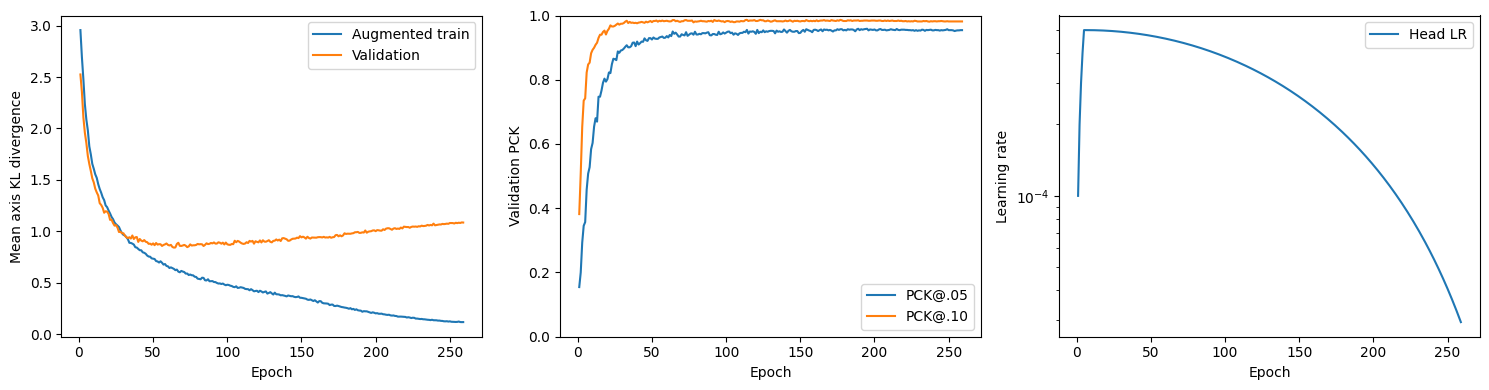

{'state': 'complete',
 'completed_epoch': 259,
 'best_epoch': 189,
 'best_val_PCK05': 0.9586894586894587,
 'reason': 'validation early stopping'}

In [12]:
sc_training_result=sc_train()
sc_display(sc_training_result)

### 10.7 Evaluate the validation-selected checkpoint and compare

Evaluate once after training completes. Use identical ground-truth-box PCK@0.05/PCK@0.10, NME and AUC020 definitions to the heatmap baseline. Report per-joint and visibility slices, a train-only mean shape, and a 1,000-resample image-bootstrap PCK confidence interval. Cache predictions with the checkpoint hash, split fingerprint and annotation order.

Where the earlier run's reports are available and match this split, display a baseline comparison without loading or modifying its model. If its cached test predictions also match, compute a **paired** image-bootstrap interval for the PCK difference. The same test set was already inspected; use validation for any further tuning. Since augmentation, resolution and schedule changed alongside the head, a difference here measures the complete recipe.

In [ ]:
def sc_file_sha256(path):
    digest=sc_hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda:handle.read(1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()
def sc_evaluate(training_result):
    if training_result.get('state')!='complete':
        raise RuntimeError('SimCC training is paused/incomplete. Resume 10.6 before test evaluation.')
    selected=sc_load_trusted(SC_RUN/'best.pt')
    assert selected['signature']==SC_SIGNATURE
    pose_model=SCSimCCPose(pretrained=False).to(SC_DEVICE)
    pose_model.load_state_dict(selected['model']); pose_model.eval()
    checkpoint_hash=sc_file_sha256(SC_RUN/'best.pt')
    path=SC_RUN/'test_predictions.npz'
    annotation_ids=sc_np.array([r['annotation_id'] for r in sc_records['test']])
    if path.exists():
        with sc_np.load(path,allow_pickle=False) as cache:
            assert str(cache['checkpoint_hash'])==checkpoint_hash, 'Selected checkpoint changed; use a new evaluation/run directory.'
            assert str(cache['split_hash'])==SC_SPLIT_HASH
            assert sc_np.array_equal(cache['annotation_ids'],annotation_ids)
            predictions=cache['predictions'].copy()
    else:
        dataset=SCSimCCDataset(sc_records['test'])
        predictions,_=sc_predict(pose_model,dataset)
        temporary=path.with_suffix('.tmp')
        with temporary.open('wb') as handle:
            sc_np.savez_compressed(handle,predictions=predictions,checkpoint_hash=checkpoint_hash,
                                   split_hash=SC_SPLIT_HASH,annotation_ids=annotation_ids)
        temporary.replace(path)
    assert predictions.shape==(len(sc_records['test']),SC_K,2) and sc_np.isfinite(predictions).all()
    errors,visibility=sc_errors(predictions,sc_records['test'])
    train_kp=sc_np.array([r['keypoints'] for r in sc_records['train']])
    boxes=sc_np.array([r['bbox'] for r in sc_records['train']])
    normalized=(train_kp[:,:,:2]-boxes[:,None,:2])/boxes[:,None,2:]
    normalized[train_kp[:,:,2]==0]=sc_np.nan
    mean_shape=sc_np.nanmean(normalized,axis=0); assert sc_np.isfinite(mean_shape).all()
    test_boxes=sc_np.array([r['bbox'] for r in sc_records['test']])
    mean_prediction=mean_shape[None]*test_boxes[:,None,2:]+test_boxes[:,None,:2]
    mean_errors,_=sc_errors(mean_prediction,sc_records['test'])
    summaries=[]; joints=[]
    for name,err in [('ResNet18 SimCC + variation',errors),('Train mean shape',mean_errors)]:
        for subset,mask in [('all labeled',visibility>0),('visible',visibility==2),('occluded',visibility==1)]:
            summaries.append(dict(model=name,subset=subset,**sc_summary(err,mask)))
    for j,name in enumerate(SC_NAMES):
        for subset,mask in [('all labeled',visibility[:,j]>0),('visible',visibility[:,j]==2),('occluded',visibility[:,j]==1)]:
            joints.append(dict(keypoint=name,subset=subset,**sc_summary(errors[:,j],mask)))
    summary=sc_pd.DataFrame(summaries); per_joint=sc_pd.DataFrame(joints)
    summary.to_csv(SC_RUN/'test_metrics.csv',index=False)
    per_joint.to_csv(SC_RUN/'per_joint_metrics.csv',index=False)
    rng=sc_np.random.default_rng(SC_CFG['seed']); bootstrap=[]
    for _ in range(1000):
        indices=rng.integers(0,len(errors),len(errors))
        bootstrap.append(sc_summary(errors[indices],visibility[indices]>0)['PCK05'])
    ci=sc_np.quantile(bootstrap,[.025,.975]).tolist()
    report=dict(checkpoint_epoch=selected['completed_epoch'],checkpoint_sha256=checkpoint_hash,
                validation_PCK05=selected['validation']['PCK05'],test_PCK05=sc_summary(errors,visibility>0)['PCK05'],
                test_PCK05_image_bootstrap_CI95=ci,split_hash=SC_SPLIT_HASH,source_commit=SC_COMMIT,
                protocol='p1A with train/val filename repair; ground-truth boxes; bbox-diagonal PCK',config=SC_CFG)
    sc_atomic_json(SC_RUN/'evaluation.json',report)
    comparison=[dict(model='ResNet18 SimCC + variation',split='validation',**selected['validation']),
                dict(model='ResNet18 SimCC + variation',split='test',**sc_summary(errors,visibility>0))]
    old_report_path=SC_BASELINE/'evaluation.json'; old_metrics_path=SC_BASELINE/'test_metrics.csv'
    old_report=None
    if old_report_path.exists() and old_metrics_path.exists():
        candidate=sc_json.loads(old_report_path.read_text())
        if candidate.get('split_hash')==SC_SPLIT_HASH:
            old_report=candidate
            old_metrics=sc_pd.read_csv(old_metrics_path)
            old_all=old_metrics[(old_metrics['model']=='ResNet18 heatmaps')&(old_metrics['subset']=='all labeled')]
            if len(old_all)==1:
                old_row=old_all.iloc[0].to_dict()
                comparison.append(dict(model='ResNet18 heatmaps',split='test',
                                       **{key:old_row[key] for key in ('count','PCK05','PCK10','NME','AUC020')}))
            comparison.append(dict(model='ResNet18 heatmaps',split='validation',PCK05=candidate['validation_PCK05']))
        else: print('Baseline report has a different split: comparison skipped.')
    comparison=sc_pd.DataFrame(comparison)
    comparison.to_csv(SC_RUN/'baseline_comparison.csv',index=False)
    old_cache_path=SC_BASELINE/'test_predictions.npz'
    if old_report is not None and old_cache_path.exists():
        with sc_np.load(old_cache_path,allow_pickle=False) as old_cache:
            if str(old_cache['checkpoint_hash'])==old_report['checkpoint_sha256']:
                old_pred=old_cache['predictions'].copy()
                assert old_pred.shape==predictions.shape
                old_errors,_=sc_errors(old_pred,sc_records['test'])
                rng=sc_np.random.default_rng(SC_CFG['seed']); differences=[]
                for _ in range(1000):
                    indices=rng.integers(0,len(errors),len(errors)); mask=visibility[indices]>0
                    differences.append(sc_summary(errors[indices],mask)['PCK05']-sc_summary(old_errors[indices],mask)['PCK05'])
                paired=dict(PCK05_difference=report['test_PCK05']-old_report['test_PCK05'],
                            image_paired_bootstrap_CI95=sc_np.quantile(differences,[.025,.975]).tolist(),
                            simcc_checkpoint=checkpoint_hash,heatmap_checkpoint=old_report['checkpoint_sha256'],
                            note='Same test images; difference includes head, augmentation, resolution and schedule changes.')
                sc_atomic_json(SC_RUN/'paired_comparison.json',paired)
                print('Paired test comparison:',paired)
    sc_display(summary.round(4)); sc_display(per_joint[per_joint['subset']=='all labeled'].round(4))
    sc_display(comparison.round(4)); print('PCK05 image-bootstrap 95% CI:',ci)
    return dict(model=pose_model,predictions=predictions,errors=errors,visibility=visibility,
                mean_errors=mean_errors,per_joint=per_joint,summary=summary,report=report,comparison=comparison)
sc_evaluation=sc_evaluate(sc_training_result)

### 10.8 Plots, difficult examples, inference and speed

Show fixed random examples plus the largest test errors; green crosses are labels and red points are predictions. PCK curves and joint scores use all labeled joints. The network benchmark excludes detection, image decoding, cropping and coordinate decoding, and explicitly reports its batch size. It does not measure end-to-end pipeline latency.

In [ ]:
sc_eval_errors=sc_evaluation['errors']; sc_eval_vis=sc_evaluation['visibility']
sc_eval_fig,sc_eval_axes=sc_plt.subplots(1,3,figsize=(18,5))
sc_thresholds=sc_np.linspace(0,.2,101)
for sc_name,sc_err in [('SimCC + variation',sc_eval_errors),('Mean shape',sc_evaluation['mean_errors'])]:
    sc_eval_axes[0].plot(sc_thresholds,[(sc_err[sc_eval_vis>0]<=t).mean() for t in sc_thresholds],label=sc_name)
sc_eval_axes[0].set(xlabel='Error / original bbox diagonal',ylabel='PCK',ylim=(0,1)); sc_eval_axes[0].legend()
sc_joint_plot=sc_evaluation['per_joint'].query("subset == 'all labeled'")
sc_eval_axes[1].barh(sc_joint_plot.keypoint,sc_joint_plot.PCK05)
sc_eval_axes[1].set(xlabel='Test PCK@.05',xlim=(0,1)); sc_eval_axes[1].invert_yaxis()
for sc_visibility,sc_label in [(2,'Visible'),(1,'Occluded')]:
    sc_values=sc_eval_errors[sc_eval_vis==sc_visibility]
    if len(sc_values):
        sc_eval_axes[2].hist(sc_values,bins=sc_np.linspace(0,.4,30),alpha=.5,label=sc_label,density=True)
sc_eval_axes[2].set(xlabel='Normalized error (display range 0 to .4)',ylabel='Density'); sc_eval_axes[2].legend()
sc_eval_fig.tight_layout(); sc_eval_fig.savefig(SC_RUN/'test_performance.png',dpi=150)
sc_plt.show(); sc_plt.close(sc_eval_fig)
def sc_show_predictions(indices,title,filename):
    figure,axes=sc_plt.subplots(2,3,figsize=(15,8))
    for ax,index in zip(axes.flat,indices):
        row=sc_records['test'][int(index)]; image,kp=sc_crop(row); geometry=sc_geometry(row['bbox'])
        points=(sc_evaluation['predictions'][index]-geometry[:2])/geometry[2:]*[SC_W,SC_H]
        mask=kp[:,2]>0
        ax.imshow(image); ax.scatter(kp[mask,0],kp[mask,1],c='lime',marker='x',s=25,label='Label')
        ax.scatter(points[mask,0],points[mask,1],c='red',s=12,label='Prediction')
        for j in sc_np.flatnonzero(mask):
            ax.plot([kp[j,0],points[j,0]],[kp[j,1],points[j,1]],color='yellow',alpha=.5,lw=.6)
        ax.set_title(f"Image {row['image_id']} | NME {sc_eval_errors[index,mask].mean():.3f}"); ax.axis('off')
    axes.flat[0].legend(loc='lower left',fontsize=8)
    figure.suptitle(title); figure.tight_layout(); figure.savefig(SC_RUN/filename,dpi=140)
    sc_plt.show(); sc_plt.close(figure)
sc_example_count=min(6,len(sc_eval_errors))
sc_show_predictions(sc_np.random.default_rng(SC_CFG['seed']).choice(len(sc_eval_errors),sc_example_count,replace=False),
                    'SimCC: fixed random test examples','test_examples.png')
sc_image_errors=sc_np.nanmean(sc_np.where(sc_eval_vis>0,sc_eval_errors,sc_np.nan),axis=1)
sc_show_predictions(sc_np.argsort(sc_image_errors)[-sc_example_count:][::-1],
                    'SimCC: largest test errors','test_failures.png')
@sc_torch.no_grad()
def sc_benchmark_network(pose_model):
    pose_model.eval(); batch=SC_CFG['batch_size']
    sample=sc_torch.zeros(batch,3,SC_H,SC_W,device=SC_DEVICE)
    for _ in range(10): pose_model(sample)
    if SC_DEVICE.type=='cuda': sc_torch.cuda.synchronize(); sc_torch.cuda.reset_peak_memory_stats()
    timings=[]
    for _ in range(30):
        begin=sc_time.perf_counter(); pose_model(sample)
        if SC_DEVICE.type=='cuda': sc_torch.cuda.synchronize()
        timings.append(sc_time.perf_counter()-begin)
    result=dict(device=str(SC_DEVICE),batch_size=batch,precision='float32',width=SC_W,height=SC_H,
                crop_network_ms_per_image=1000*float(sc_np.mean(timings))/batch,
                crop_network_images_per_second=batch/float(sc_np.mean(timings)),
                parameters=sum(p.numel() for p in pose_model.parameters()),
                peak_cuda_MB=sc_torch.cuda.max_memory_allocated()/1024**2 if SC_DEVICE.type=='cuda' else None,
                excludes=['box detection','image decoding','cropping','coordinate decoding'])
    sc_atomic_json(SC_RUN/'benchmark.json',result); return result
sc_display(sc_pd.DataFrame([sc_benchmark_network(sc_evaluation['model'])]))
@sc_torch.no_grad()
def sc_infer_cattle(image_path,bbox):
    path=SCPath(image_path)
    with SCImage.open(path) as image: width,height=image.size
    x,y,w,h=map(float,bbox)
    assert x>=0 and y>=0 and w>0 and h>0 and x+w<=width and y+h<=height
    row=dict(path=str(path),bbox=[x,y,w,h],keypoints=sc_np.zeros((SC_K,3)).tolist())
    crop,_=sc_crop(row)
    image=sc_torch.from_numpy(((crop.astype(sc_np.float32)/255-SC_MEAN)/SC_STD).transpose(2,0,1).copy())[None].to(SC_DEVICE)
    pose_model=sc_evaluation['model']; pose_model.eval()
    prediction=sc_to_original(sc_decode(pose_model(image)).cpu().numpy(),[row])[0]
    return sc_pd.DataFrame(dict(keypoint=SC_NAMES,x=prediction[:,0],y=prediction[:,1]))
# After training/evaluation: sc_infer_cattle('path/to/cow.jpg', [100,120,600,420])
print('SimCC artifacts:',SC_RUN)

### 10.9 Reading this experiment's results

Use `baseline_comparison.csv` for the same-split accuracy comparison, `paired_comparison.json` for paired test uncertainty when available, and `per_joint_metrics.csv` to check the hind legs and feet. Inspect random and difficult examples for side swaps and anatomically implausible output. PCK is still computed with oracle cattle boxes and is not detection AP or a health/performance diagnosis.

The validation–test source gap may remain: stronger augmentation and SimCC are hypotheses to evaluate, not guaranteed improvements. Preserve this run directory and choose future configurations using validation data. Keep original sections 1–9 as the heatmap baseline.